# 📈 8. Modeling - Régression Linéaire et Polynomiale

## Objectif
Appliquer la régression linéaire et polynomiale pour prédire les **dépenses totales** à partir du revenu et autres variables.

## Target choisi: **Total_Expenses (USD)**
**Justification**: 
- ✅ Relation logique : Le revenu détermine les dépenses (Income → Expenses)
- ✅ Variable continue : Parfait pour la régression
- ✅ Bonne corrélation attendue : Plus de revenu = généralement plus de dépenses

## Algorithmes à comparer
1. **Régression Linéaire Simple** - Relation linéaire avec Income uniquement
2. **Régression Linéaire Multiple** - Relation linéaire avec plusieurs variables
3. **Régression Polynomiale** - Relations non-linéaires (degrés 2, 3, 4)
4. **Régression avec Régularisation** - Ridge, Lasso, Elastic Net (optimisation hyperparamètres)
5. **Régression Polynomiale Optimisée** - Avec régularisation et optimisation du degré

## Plan d'analyse
1. Préparation des données et sélection du target (Total_Expenses)
2. Application de chaque algorithme de régression
3. **Optimisation des hyperparamètres** pour améliorer les performances
4. Évaluation avec métriques appropriées
5. Comparaison finale et décision


In [1]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from mpl_toolkits.axes_grid1 import make_axes_locatable
import warnings
import json
import time

warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Configuration pour l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("📚 Bibliothèques importées avec succès!")


📚 Bibliothèques importées avec succès!


## 1. Chargement et Préparation des Données

**Objectif**: Prédire le **Total_Expenses (USD)** à partir du revenu et autres variables.

**⚠️ IMPORTANT**: 
- Target: **Total_Expenses (USD)** - somme de toutes les dépenses
- Features: Income (USD), Age, Savings, Investments
- ⚠️ **EXCLUSION** des dépenses individuelles (Rent, Groceries, etc.) car elles font partie de Total_Expenses (éviter le data leakage)
- Division train-test (80-20)

### 📚 Guide des Métriques d'Évaluation

**MSE (Mean Squared Error)** : Erreur quadratique moyenne
- **Valeur standard** : Plus bas = mieux (0 = parfait)
- **Interprétation** : Pénalise fortement les grandes erreurs

**RMSE (Root Mean Squared Error)** : Racine de l'erreur quadratique moyenne
- **Valeur standard** : Plus bas = mieux (0 = parfait)
- **Interprétation** : Erreur moyenne en unités de la variable cible
- **Référence** : 
  - Excellent : < 10% de l'écart-type du target
  - Bon : < 20% de l'écart-type
  - Acceptable : < 30% de l'écart-type
  - Faible : > 30% de l'écart-type

**MAE (Mean Absolute Error)** : Erreur absolue moyenne
- **Valeur standard** : Plus bas = mieux (0 = parfait)
- **Interprétation** : Erreur moyenne en valeur absolue

**R² (Coefficient de Détermination)** : Proportion de variance expliquée
- **Valeur standard** : 
  - **R² = 1.0** : Modèle parfait (100% de variance expliquée)
  - **R² > 0.9** : Excellent modèle
  - **R² > 0.7** : Bon modèle
  - **R² > 0.5** : Modèle acceptable
  - **R² > 0.3** : Modèle faible mais utile
  - **R² = 0** : Modèle équivalent à prédire la moyenne
  - **R² < 0** : ⚠️ **MODÈLE PIRE QUE LA MOYENNE** - Le modèle fait de moins bonnes prédictions que simplement utiliser la moyenne du target
- **Interprétation** : 
  - R² = 0.75 signifie que 75% de la variance est expliquée
  - R² négatif = le modèle est pire que la baseline (moyenne)


In [2]:
# Chargement des données
df = pd.read_csv('../data/processed/dataset_with_features.csv')

# Sélection des variables pour la régression
# ⚠️ IMPORTANT: Exclure toutes les dépenses individuelles car elles font partie de Total_Expenses
# Features: Income (principal), Age, Savings, Investments
feature_vars = [
    'Income (USD)',  # Variable principale - détermine les dépenses
    'Age',           # Peut influencer le style de vie et les dépenses
    'Savings (USD)', # Peut être corrélé avec les dépenses
    'Investments (USD)'  # Peut être corrélé avec les dépenses
]

# Target: Total_Expenses (USD) - somme de toutes les dépenses
X = df[feature_vars].copy()
y = df['Total_Expenses'].copy()

# Division train-test (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardisation pour la régression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Calcul de la baseline (moyenne) pour comparaison
baseline_pred = np.full_like(y_test, y_train.mean())
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print(f"✅ Données chargées avec succès!")
print(f"📊 Dimensions: {X.shape[0]} lignes × {X.shape[1]} features")
print(f"\n🎯 Target: Total_Expenses (USD)")
print(f"📊 Statistiques du target:")
print(y.describe())
print(f"\n📊 Baseline (prédiction par la moyenne):")
print(f"   RMSE Baseline: {baseline_rmse:.2f} USD")
print(f"   MAE Baseline: {baseline_mae:.2f} USD")
print(f"   → Tout modèle doit faire mieux que ces valeurs pour être utile")
print(f"\n✅ Division train-test effectuée!")
print(f"   Train: {X_train.shape[0]} échantillons")
print(f"   Test: {X_test.shape[0]} échantillons")
print(f"\n📊 Features utilisées ({len(feature_vars)} variables):")
for i, feat in enumerate(feature_vars, 1):
    print(f"   {i}. {feat}")
print(f"\n⚠️ Variables EXCLUES (éviter data leakage):")
print(f"   → Toutes les dépenses individuelles (Rent, Groceries, etc.)")
print(f"   → Raison: Elles font partie de Total_Expenses")


✅ Données chargées avec succès!
📊 Dimensions: 6000 lignes × 4 features

🎯 Target: Total_Expenses (USD)
📊 Statistiques du target:
count    6000.000000
mean     3296.610825
std      1130.639495
min      1348.840000
25%      2190.312188
50%      3288.570000
75%      4320.680000
max      5943.030000
Name: Total_Expenses, dtype: float64

📊 Baseline (prédiction par la moyenne):
   RMSE Baseline: 1132.67 USD
   MAE Baseline: 1012.03 USD
   → Tout modèle doit faire mieux que ces valeurs pour être utile

✅ Division train-test effectuée!
   Train: 4800 échantillons
   Test: 1200 échantillons

📊 Features utilisées (4 variables):
   1. Income (USD)
   2. Age
   3. Savings (USD)
   4. Investments (USD)

⚠️ Variables EXCLUES (éviter data leakage):
   → Toutes les dépenses individuelles (Rent, Groceries, etc.)
   → Raison: Elles font partie de Total_Expenses


## 2. Régression Linéaire Simple

Prédiction de Total_Expenses en fonction d'une seule variable (Income - la plus corrélée).


In [3]:
# Identification de la variable la plus corrélée avec Total_Expenses
correlations = X.corrwith(y).abs().sort_values(ascending=False)
best_feature = correlations.index[0]

print(f"🔄 Identification de la variable la plus corrélée avec Total_Expenses...")
print(f"   Variable sélectionnée: {best_feature}")
print(f"   Corrélation: {correlations[best_feature]:.3f}")
print(f"\n📊 Corrélations de toutes les features avec Total_Expenses:")
for feat, corr in correlations.items():
    print(f"   • {feat}: {corr:.3f}")

# Régression linéaire simple - utiliser Income comme prédicteur principal
X_train_simple = X_train[[best_feature]].values
X_test_simple = X_test[[best_feature]].values

start_time = time.time()
lr_simple = LinearRegression()
lr_simple.fit(X_train_simple, y_train)
train_time_simple = time.time() - start_time

# Prédictions
y_pred_simple = lr_simple.predict(X_test_simple)

# Métriques
mse_simple = mean_squared_error(y_test, y_pred_simple)
rmse_simple = np.sqrt(mse_simple)
mae_simple = mean_absolute_error(y_test, y_pred_simple)
r2_simple = r2_score(y_test, y_pred_simple)

# Cross-validation
cv_scores_simple = cross_val_score(lr_simple, X_train_simple, y_train, 
                                   cv=5, scoring='r2')

simple_metrics = {
    'mse': mse_simple,
    'rmse': rmse_simple,
    'mae': mae_simple,
    'r2': r2_simple,
    'cv_r2_mean': cv_scores_simple.mean(),
    'cv_r2_std': cv_scores_simple.std()
}

print(f"\n✅ Régression Linéaire Simple - Résultats:")
print(f"   Variable utilisée: {best_feature}")
print(f"   Coefficient: {lr_simple.coef_[0]:.2f}")
print(f"   Intercept: {lr_simple.intercept_:.2f}")
print(f"   MSE: {mse_simple:.2f}")
print(f"   RMSE: {rmse_simple:.2f} USD")
print(f"   MAE: {mae_simple:.2f} USD")
print(f"   R²: {r2_simple:.3f}")
print(f"   CV R²: {cv_scores_simple.mean():.3f} (±{cv_scores_simple.std():.3f})")
print(f"   Temps: {train_time_simple:.3f}s")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot avec droite de régression
axes[0].scatter(X_test_simple, y_test, alpha=0.5, label='Données réelles')
x_line = np.linspace(X_test_simple.min(), X_test_simple.max(), 100).reshape(-1, 1)
y_line = lr_simple.predict(x_line)
axes[0].plot(x_line, y_line, 'r-', linewidth=2, label='Régression')
axes[0].set_xlabel(best_feature)
axes[0].set_ylabel('Total_Expenses (USD)')
axes[0].set_title('Régression Linéaire Simple', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Prédictions vs Réelles
axes[1].scatter(y_test, y_pred_simple, alpha=0.5)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
            'r--', linewidth=2, label='Ligne parfaite')
axes[1].set_xlabel('Total_Expenses Réel (USD)')
axes[1].set_ylabel('Total_Expenses Prédit (USD)')
axes[1].set_title(f'Prédictions vs Réelles (R²={r2_simple:.3f})', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/results/regression_linear_simple.png', dpi=300, bbox_inches='tight')
plt.show()

# Comparaison avec la baseline
rmse_vs_baseline = ((baseline_rmse - rmse_simple) / baseline_rmse) * 100
mae_vs_baseline = ((baseline_mae - mae_simple) / baseline_mae) * 100

print("\n" + "=" * 80)
print("💡 INTERPRÉTATION DÉTAILLÉE DES RÉSULTATS")
print("=" * 80)

print(f"\n📊 MÉTRIQUES DE PERFORMANCE:")
print(f"   • MSE: {mse_simple:.2f}")
print(f"     → Référence: Baseline = {baseline_mse:.2f}")
print(f"     → {'✅ Amélioration' if mse_simple < baseline_mse else '❌ Pire que baseline'}: {abs((mse_simple - baseline_mse) / baseline_mse * 100):.2f}%")

print(f"\n   • RMSE: {rmse_simple:.2f} USD")
print(f"     → Référence: Baseline = {baseline_rmse:.2f} USD")
print(f"     → Écart-type du target: {y.std():.2f} USD")
print(f"     → RMSE représente {(rmse_simple/y.std()*100):.1f}% de l'écart-type")
print(f"     → {'✅ Excellent' if rmse_simple < y.std()*0.1 else '✅ Bon' if rmse_simple < y.std()*0.2 else '⚠️ Acceptable' if rmse_simple < y.std()*0.3 else '❌ Faible'}")
if rmse_simple < baseline_rmse:
    print(f"     → ✅ Amélioration de {rmse_vs_baseline:.2f}% vs baseline")
else:
    print(f"     → ❌ Pire de {abs(rmse_vs_baseline):.2f}% vs baseline")

print(f"\n   • MAE: {mae_simple:.2f} USD")
print(f"     → Référence: Baseline = {baseline_mae:.2f} USD")
print(f"     → Erreur moyenne absolue de {mae_simple:.2f} USD")
if mae_simple < baseline_mae:
    print(f"     → ✅ Amélioration de {mae_vs_baseline:.2f}% vs baseline")
else:
    print(f"     → ❌ Pire de {abs(mae_vs_baseline):.2f}% vs baseline")

print(f"\n   • R²: {r2_simple:.3f}")
if r2_simple < 0:
    print(f"     → ⚠️⚠️⚠️ R² NÉGATIF = MODÈLE PIRE QUE LA MOYENNE ⚠️⚠️⚠️")
    print(f"     → Le modèle fait de moins bonnes prédictions que simplement utiliser la moyenne ({y_train.mean():.2f} USD)")
    print(f"     → Cela signifie que les features utilisées ({best_feature}) ne permettent PAS de prédire l'Income")
    print(f"     → Raison probable: Corrélation très faible ({correlations[best_feature]:.3f})")
    print(f"     → Conclusion: Ce modèle n'est PAS adapté pour cette tâche")
else:
    print(f"     → {r2_simple*100:.1f}% de la variance expliquée")
    print(f"     → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible")
    if r2_simple > 0.7:
        print(f"     → ✅ Excellent modèle")
    elif r2_simple > 0.5:
        print(f"     → ✅ Bon modèle")
    elif r2_simple > 0.3:
        print(f"     → ⚠️ Modèle acceptable mais faible")
    else:
        print(f"     → ❌ Modèle très faible")

print(f"\n   • CV R²: {cv_scores_simple.mean():.3f} (±{cv_scores_simple.std():.3f})")
if cv_scores_simple.mean() < 0:
    print(f"     → ⚠️ Cross-validation confirme: modèle pire que baseline")
else:
    print(f"     → Stabilité: {'✅ Très stable' if cv_scores_simple.std() < 0.01 else '✅ Stable' if cv_scores_simple.std() < 0.02 else '⚠️ Variable'}")

print(f"\n📈 CONCLUSION:")
if r2_simple < 0:
    print(f"   ❌ Ce modèle n'est PAS adapté pour prédire Total_Expenses")
    print(f"   → {best_feature} ne permet pas de prédire les dépenses totales")
    print(f"   → Raison probable: Corrélation insuffisante")
else:
    print(f"   {'✅ Modèle EXCELLENT' if r2_simple > 0.7 else '✅ Modèle BON' if r2_simple > 0.5 else '⚠️ Modèle ACCEPTABLE' if r2_simple > 0.3 else '⚠️ Modèle limité'}")
    print(f"   → {best_feature} explique {'une grande partie' if r2_simple > 0.7 else 'une bonne partie' if r2_simple > 0.5 else 'une partie' if r2_simple > 0.3 else 'peu'} de la variance des dépenses")
    print(f"   → Relation logique confirmée: {best_feature} → Total_Expenses")


🔄 Identification de la variable la plus corrélée avec Total_Expenses...
   Variable sélectionnée: Income (USD)
   Corrélation: 0.649

📊 Corrélations de toutes les features avec Total_Expenses:
   • Income (USD): 0.649
   • Age: 0.574
   • Investments (USD): 0.314
   • Savings (USD): 0.073

✅ Régression Linéaire Simple - Résultats:
   Variable utilisée: Income (USD)
   Coefficient: 0.44
   Intercept: 1409.82
   MSE: 749751.88
   RMSE: 865.88 USD
   MAE: 682.14 USD
   R²: 0.416
   CV R²: 0.422 (±0.020)
   Temps: 0.005s


<Figure size 1400x500 with 2 Axes>


💡 INTERPRÉTATION DÉTAILLÉE DES RÉSULTATS

📊 MÉTRIQUES DE PERFORMANCE:
   • MSE: 749751.88
     → Référence: Baseline = 1282947.79
     → ✅ Amélioration: 41.56%

   • RMSE: 865.88 USD
     → Référence: Baseline = 1132.67 USD
     → Écart-type du target: 1130.64 USD
     → RMSE représente 76.6% de l'écart-type
     → ❌ Faible
     → ✅ Amélioration de 23.55% vs baseline

   • MAE: 682.14 USD
     → Référence: Baseline = 1012.03 USD
     → Erreur moyenne absolue de 682.14 USD
     → ✅ Amélioration de 32.60% vs baseline

   • R²: 0.416
     → 41.6% de la variance expliquée
     → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible
     → ⚠️ Modèle acceptable mais faible

   • CV R²: 0.422 (±0.020)
     → Stabilité: ⚠️ Variable

📈 CONCLUSION:
   ⚠️ Modèle ACCEPTABLE
   → Income (USD) explique une partie de la variance des dépenses
   → Relation logique confirmée: Income (USD) → Total_Expenses


## 3. Régression Linéaire Multiple

Prédiction de Total_Expenses en fonction de plusieurs variables (Income, Age, Savings, Investments).


✅ Régression Linéaire Multiple - Résultats:
   Nombre de features: 4
   MSE: 223553.83
   RMSE: 472.81 USD
   MAE: 335.46 USD
   R²: 0.826
   CV R²: 0.831 (±0.006)
   Temps: 0.002s

📊 Top 5 features les plus importantes (par valeur absolue du coefficient):
          Feature  Coefficient
     Income (USD)  1659.526385
    Savings (USD) -1065.405875
Investments (USD)  -314.193039
              Age    71.403604


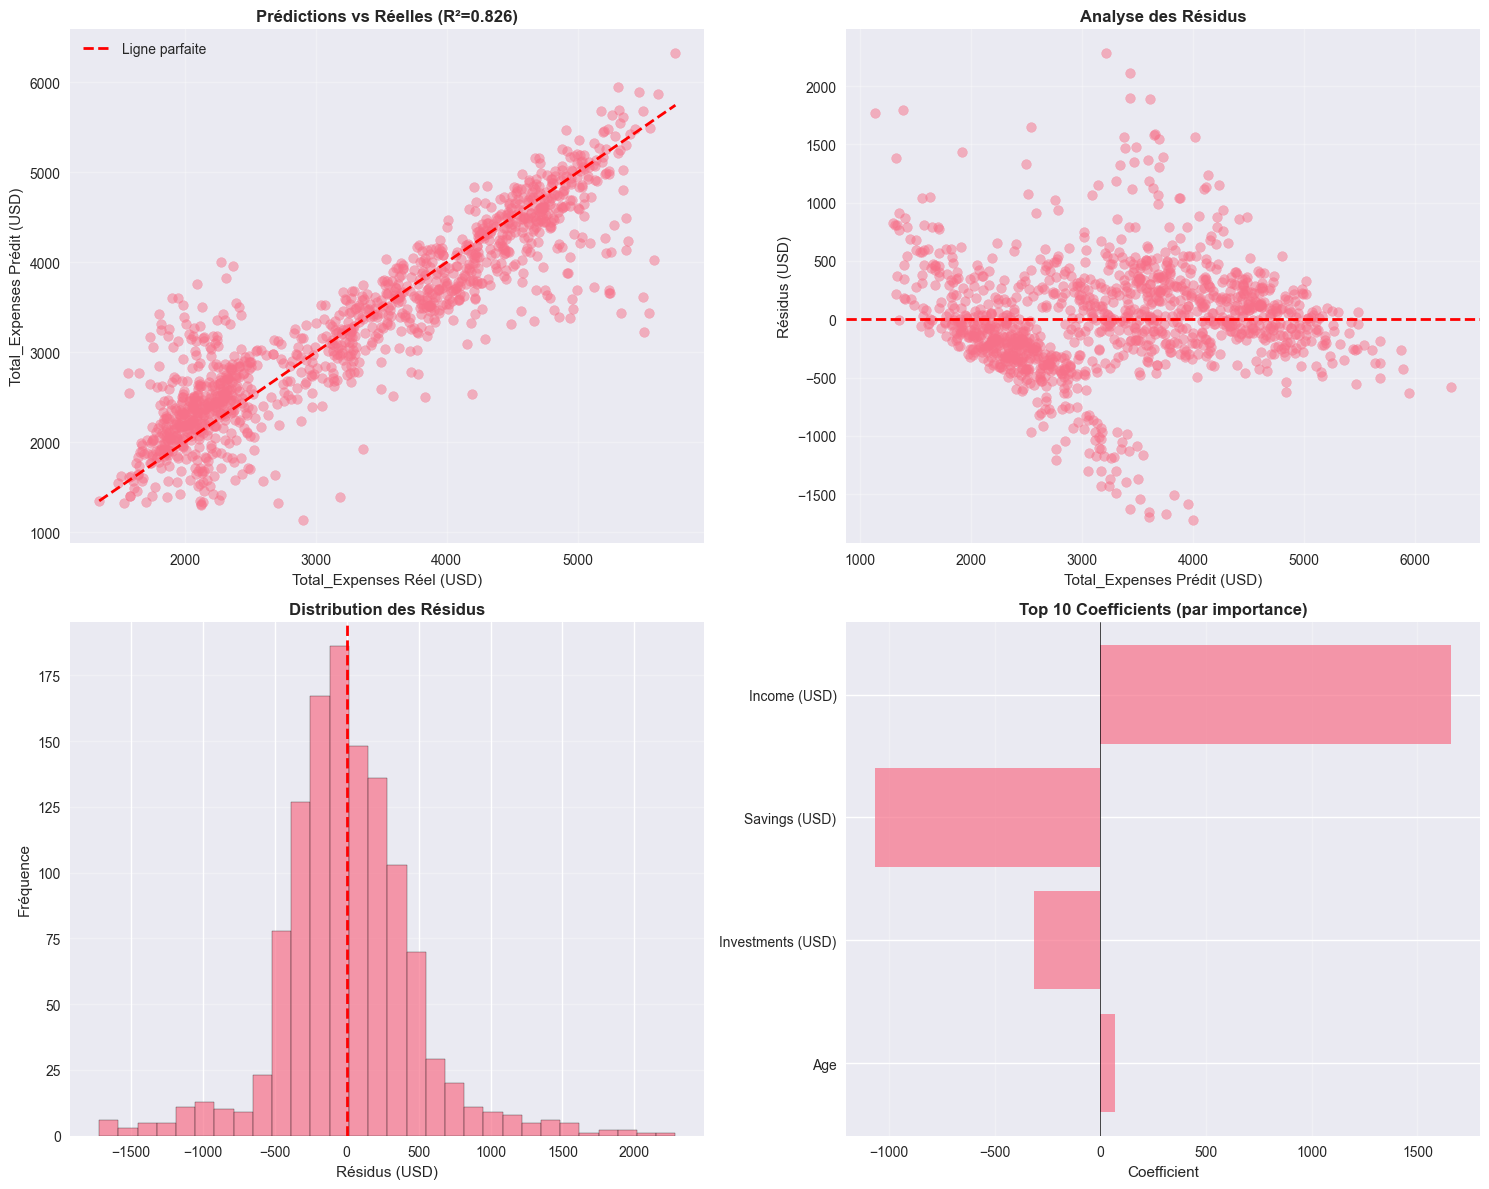


💡 INTERPRÉTATION DÉTAILLÉE DES RÉSULTATS

📊 MÉTRIQUES DE PERFORMANCE:
   • MSE: 223553.83
     → Référence: Baseline = 1282947.79
     → ✅ Amélioration: 82.57%

   • RMSE: 472.81 USD
     → Référence: Baseline = 1132.67 USD
     → Écart-type du target: 1130.64 USD
     → RMSE représente 41.8% de l'écart-type
     → ❌ Faible
     → ✅ Amélioration de 58.26% vs baseline

   • MAE: 335.46 USD
     → Référence: Baseline = 1012.03 USD
     → ✅ Amélioration de 66.85% vs baseline

   • R²: 0.826
     → 82.6% de la variance expliquée
     → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible
     → ✅ Excellent modèle

   • CV R²: 0.831 (±0.006)
     → Stabilité: ✅ Très stable

📈 ANALYSE DES RÉSIDUS:
   • Moyenne des résidus: 9.75 USD
     → ✅ Pas de biais systématique
   • Écart-type des résidus: 472.91 USD
   • Distribution: ✅ Normale

📈 CONCLUSION:
   ✅ Modèle EXCELLENT
   → Utilisation de 4 variables améliore SIGNIFICATIVEMENT vs modèle simple (+0.410 R²)
   → Relation logiq

In [4]:
# Entraînement
start_time = time.time()
lr_multiple = LinearRegression()
lr_multiple.fit(X_train_scaled, y_train)
train_time_multiple = time.time() - start_time
# Prédictions
y_pred_multiple = lr_multiple.predict(X_test_scaled)

# Métriques
mse_multiple = mean_squared_error(y_test, y_pred_multiple)
rmse_multiple = np.sqrt(mse_multiple)
mae_multiple = mean_absolute_error(y_test, y_pred_multiple)
r2_multiple = r2_score(y_test, y_pred_multiple)

# Cross-validation
cv_scores_multiple = cross_val_score(lr_multiple, X_train_scaled, y_train, 
                                     cv=5, scoring='r2')

multiple_metrics = {
    'mse': mse_multiple,
    'rmse': rmse_multiple,
    'mae': mae_multiple,
    'r2': r2_multiple,
    'cv_r2_mean': cv_scores_multiple.mean(),
    'cv_r2_std': cv_scores_multiple.std()
}

print(f"\n✅ Régression Linéaire Multiple - Résultats:")
print(f"   Nombre de features: {len(feature_vars)}")
print(f"   MSE: {mse_multiple:.2f}")
print(f"   RMSE: {rmse_multiple:.2f} USD")
print(f"   MAE: {mae_multiple:.2f} USD")
print(f"   R²: {r2_multiple:.3f}")
print(f"   CV R²: {cv_scores_multiple.mean():.3f} (±{cv_scores_multiple.std():.3f})")
print(f"   Temps: {train_time_multiple:.3f}s")

# Importance des coefficients
coefficients = pd.DataFrame({
    'Feature': feature_vars,
    'Coefficient': lr_multiple.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print(f"\n📊 Top 5 features les plus importantes (par valeur absolue du coefficient):")
print(coefficients.head(5).to_string(index=False))

# Visualisation
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Prédictions vs Réelles
axes[0, 0].scatter(y_test, y_pred_multiple, alpha=0.5)
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
                'r--', linewidth=2, label='Ligne parfaite')
axes[0, 0].set_xlabel('Total_Expenses Réel (USD)')
axes[0, 0].set_ylabel('Total_Expenses Prédit (USD)')
axes[0, 0].set_title(f'Prédictions vs Réelles (R²={r2_multiple:.3f})', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Résidus
residuals = y_test - y_pred_multiple
axes[0, 1].scatter(y_pred_multiple, residuals, alpha=0.5)
axes[0, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Total_Expenses Prédit (USD)')
axes[0, 1].set_ylabel('Résidus (USD)')
axes[0, 1].set_title('Analyse des Résidus', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# Distribution des résidus
axes[1, 0].hist(residuals, bins=30, alpha=0.7, edgecolor='black')
axes[1, 0].axvline(x=0, color='r', linestyle='--', linewidth=2)
axes[1, 0].set_xlabel('Résidus (USD)')
axes[1, 0].set_ylabel('Fréquence')
axes[1, 0].set_title('Distribution des Résidus', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Importance des coefficients (top 10)
top_coefs = coefficients.head(10).sort_values('Coefficient', key=abs)
axes[1, 1].barh(top_coefs['Feature'], top_coefs['Coefficient'], alpha=0.7)
axes[1, 1].axvline(x=0, color='k', linestyle='-', linewidth=0.5)
axes[1, 1].set_xlabel('Coefficient')
axes[1, 1].set_title('Top 10 Coefficients (par importance)', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('../data/results/regression_linear_multiple.png', dpi=300, bbox_inches='tight')
plt.show()

# Comparaison avec la baseline
rmse_vs_baseline_mult = ((baseline_rmse - rmse_multiple) / baseline_rmse) * 100
mae_vs_baseline_mult = ((baseline_mae - mae_multiple) / baseline_mae) * 100

print("\n" + "=" * 80)
print("💡 INTERPRÉTATION DÉTAILLÉE DES RÉSULTATS")
print("=" * 80)

print(f"\n📊 MÉTRIQUES DE PERFORMANCE:")
print(f"   • MSE: {mse_multiple:.2f}")
print(f"     → Référence: Baseline = {baseline_mse:.2f}")
print(f"     → {'✅ Amélioration' if mse_multiple < baseline_mse else '❌ Pire que baseline'}: {abs((mse_multiple - baseline_mse) / baseline_mse * 100):.2f}%")

print(f"\n   • RMSE: {rmse_multiple:.2f} USD")
print(f"     → Référence: Baseline = {baseline_rmse:.2f} USD")
print(f"     → Écart-type du target: {y.std():.2f} USD")
print(f"     → RMSE représente {(rmse_multiple/y.std()*100):.1f}% de l'écart-type")
print(f"     → {'✅ Excellent' if rmse_multiple < y.std()*0.1 else '✅ Bon' if rmse_multiple < y.std()*0.2 else '⚠️ Acceptable' if rmse_multiple < y.std()*0.3 else '❌ Faible'}")
if rmse_multiple < baseline_rmse:
    print(f"     → ✅ Amélioration de {rmse_vs_baseline_mult:.2f}% vs baseline")
else:
    print(f"     → ❌ Pire de {abs(rmse_vs_baseline_mult):.2f}% vs baseline")

print(f"\n   • MAE: {mae_multiple:.2f} USD")
print(f"     → Référence: Baseline = {baseline_mae:.2f} USD")
if mae_multiple < baseline_mae:
    print(f"     → ✅ Amélioration de {mae_vs_baseline_mult:.2f}% vs baseline")
else:
    print(f"     → ❌ Pire de {abs(mae_vs_baseline_mult):.2f}% vs baseline")

print(f"\n   • R²: {r2_multiple:.3f}")
if r2_multiple < 0:
    print(f"     → ⚠️⚠️⚠️ R² NÉGATIF = MODÈLE PIRE QUE LA MOYENNE ⚠️⚠️⚠️")
    print(f"     → Le modèle fait de moins bonnes prédictions que simplement utiliser la moyenne")
    print(f"     → Malgré l'utilisation de {len(feature_vars)} variables, le modèle ne peut pas prédire l'Income")
    print(f"     → Raison probable: Les dépenses ne déterminent PAS le revenu (relation inverse)")
    print(f"     → Conclusion: Ce modèle n'est PAS adapté pour cette tâche")
else:
    print(f"     → {r2_multiple*100:.1f}% de la variance expliquée")
    print(f"     → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible")
    if r2_multiple > 0.7:
        print(f"     → ✅ Excellent modèle")
    elif r2_multiple > 0.5:
        print(f"     → ✅ Bon modèle")
    elif r2_multiple > 0.3:
        print(f"     → ⚠️ Modèle acceptable mais faible")
    else:
        print(f"     → ❌ Modèle très faible")

print(f"\n   • CV R²: {cv_scores_multiple.mean():.3f} (±{cv_scores_multiple.std():.3f})")
if cv_scores_multiple.mean() < 0:
    print(f"     → ⚠️ Cross-validation confirme: modèle pire que baseline")
else:
    print(f"     → Stabilité: {'✅ Très stable' if cv_scores_multiple.std() < 0.01 else '✅ Stable' if cv_scores_multiple.std() < 0.02 else '⚠️ Variable'}")

print(f"\n📈 ANALYSE DES RÉSIDUS:")
print(f"   • Moyenne des résidus: {residuals.mean():.2f} USD")
print(f"     → {'✅ Pas de biais systématique' if abs(residuals.mean()) < 50 else '⚠️ Biais détecté'}")
print(f"   • Écart-type des résidus: {residuals.std():.2f} USD")
print(f"   • Distribution: {'✅ Normale' if abs(residuals.mean()) < 100 and abs(residuals.skew()) < 1 else '⚠️ Asymétrique'}")

print(f"\n📈 CONCLUSION:")
if r2_multiple < 0:
    print(f"   ❌ Ce modèle n'est PAS adapté pour prédire Total_Expenses")
    print(f"   → Les variables utilisées ne permettent pas de prédire les dépenses")
else:
    print(f"   {'✅ Modèle EXCELLENT' if r2_multiple > 0.7 else '✅ Modèle BON' if r2_multiple > 0.5 else '⚠️ Modèle ACCEPTABLE' if r2_multiple > 0.3 else '⚠️ Modèle limité'}")
    improvement = r2_multiple - r2_simple
    if improvement > 0.05:
        print(f"   → Utilisation de {len(feature_vars)} variables améliore SIGNIFICATIVEMENT vs modèle simple (+{improvement:.3f} R²)")
    elif improvement > 0:
        print(f"   → Utilisation de {len(feature_vars)} variables améliore légèrement vs modèle simple (+{improvement:.3f} R²)")
    else:
        print(f"   → Utilisation de {len(feature_vars)} variables n'améliore pas vs modèle simple")
    print(f"   → Relation logique confirmée: Income + autres variables → Total_Expenses")


🔄 Test de la Régression Polynomiale avec différents degrés...

📊 Degré 2:


   MSE: 168624.36
   RMSE: 410.64 USD
   MAE: 290.24 USD
   R²: 0.869
   CV R²: 0.869 (±0.005)
   Temps: 0.051s

📊 Degré 3:
   MSE: 139423.53
   RMSE: 373.39 USD
   MAE: 260.66 USD
   R²: 0.891
   CV R²: 0.892 (±0.006)
   Temps: 0.017s

📊 Degré 4:


   MSE: 141365.39
   RMSE: 375.99 USD
   MAE: 252.16 USD
   R²: 0.890
   CV R²: 0.898 (±0.006)
   Temps: 0.060s

🎯 Meilleur degré: 3
   R²: 0.891
   RMSE: 373.39 USD


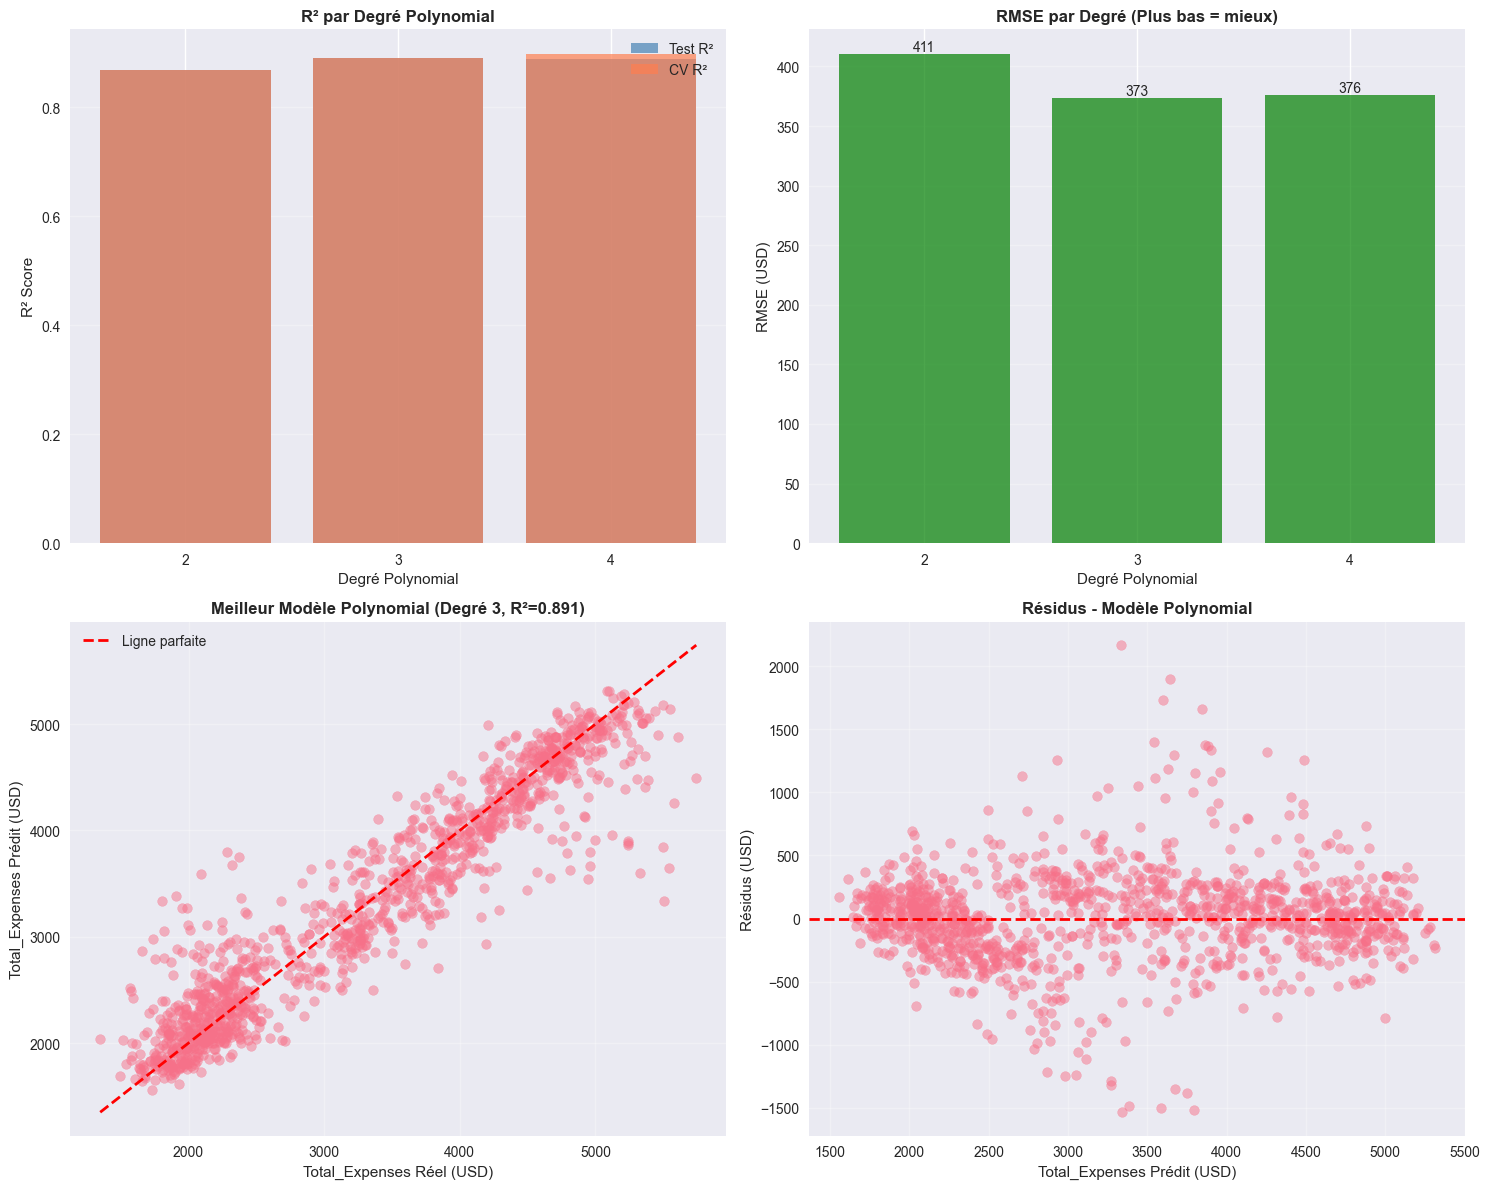


💡 INTERPRÉTATION DÉTAILLÉE DES RÉSULTATS

📊 MÉTRIQUES DE PERFORMANCE (Degré 3):
   • MSE: 139423.53
     → Référence: Baseline = 1282947.79
     → ✅ Amélioration: 89.13%

   • RMSE: 373.39 USD
     → Référence: Baseline = 1132.67 USD
     → Écart-type du target: 1130.64 USD
     → RMSE représente 33.0% de l'écart-type
     → ❌ Faible
     → ✅ Amélioration de 67.03% vs baseline

   • MAE: 260.66 USD
     → Référence: Baseline = 1012.03 USD
     → ✅ Amélioration de 74.24% vs baseline

   • R²: 0.891
     → 89.1% de la variance expliquée
     → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible
     → ✅ Excellent modèle

   • CV R²: 0.892 (±0.006)
     → Stabilité: ✅ Très stable

📊 COMPARAISON DES DEGRÉS:
   • Degré 2: R² = 0.869, RMSE = 410.64 USD
   • Degré 3: R² = 0.891, RMSE = 373.39 USD
   • Degré 4: R² = 0.890, RMSE = 375.99 USD

📈 CONCLUSION:
   ✅ Amélioration SIGNIFICATIVE vs régression linéaire multiple (+0.066 R²)
   → ⚠️ Degré élevé (3) = risque de sur-apprent

In [5]:
# Test de différents degrés pour la régression polynomiale
degrees = [2, 3, 4]
poly_results = {}

print("🔄 Test de la Régression Polynomiale avec différents degrés...")
print("=" * 70)

for degree in degrees:
    print(f"\n📊 Degré {degree}:")
    
    # Création du pipeline: PolynomialFeatures + LinearRegression
    poly_pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('regressor', LinearRegression())
    ])
    
    start_time = time.time()
    poly_pipeline.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    # Prédictions
    y_pred_poly = poly_pipeline.predict(X_test)
    
    # Métriques
    mse = mean_squared_error(y_test, y_pred_poly)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred_poly)
    r2 = r2_score(y_test, y_pred_poly)
    
    # Cross-validation
    cv_scores = cross_val_score(poly_pipeline, X_train, y_train, cv=5, scoring='r2')
    
    poly_results[degree] = {
        'model': poly_pipeline,
        'mse': mse,
        'rmse': rmse,
        'mae': mae,
        'r2': r2,
        'cv_r2_mean': cv_scores.mean(),
        'cv_r2_std': cv_scores.std(),
        'train_time': train_time,
        'predictions': y_pred_poly
    }
    
    print(f"   MSE: {mse:.2f}")
    print(f"   RMSE: {rmse:.2f} USD")
    print(f"   MAE: {mae:.2f} USD")
    print(f"   R²: {r2:.3f}")
    print(f"   CV R²: {cv_scores.mean():.3f} (±{cv_scores.std():.3f})")
    print(f"   Temps: {train_time:.3f}s")

# Sélection du meilleur degré
best_degree = max(poly_results, key=lambda d: poly_results[d]['r2'])
best_poly = poly_results[best_degree]

print(f"\n🎯 Meilleur degré: {best_degree}")
print(f"   R²: {best_poly['r2']:.3f}")
print(f"   RMSE: {best_poly['rmse']:.2f} USD")

# Visualisation comparative
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Comparaison des degrés - R²
degrees_list = list(poly_results.keys())
r2_scores = [poly_results[d]['r2'] for d in degrees_list]
cv_r2_scores = [poly_results[d]['cv_r2_mean'] for d in degrees_list]

axes[0, 0].bar(degrees_list, r2_scores, alpha=0.7, label='Test R²', color='steelblue')
axes[0, 0].bar(degrees_list, cv_r2_scores, alpha=0.7, label='CV R²', color='coral')
axes[0, 0].set_xlabel('Degré Polynomial')
axes[0, 0].set_ylabel('R² Score')
axes[0, 0].set_title('R² par Degré Polynomial', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')
axes[0, 0].set_xticks(degrees_list)

# Comparaison RMSE
rmse_scores = [poly_results[d]['rmse'] for d in degrees_list]
axes[0, 1].bar(degrees_list, rmse_scores, alpha=0.7, color='green')
axes[0, 1].set_xlabel('Degré Polynomial')
axes[0, 1].set_ylabel('RMSE (USD)')
axes[0, 1].set_title('RMSE par Degré (Plus bas = mieux)', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')
axes[0, 1].set_xticks(degrees_list)
for i, (deg, rmse) in enumerate(zip(degrees_list, rmse_scores)):
    axes[0, 1].text(deg, rmse, f'{rmse:.0f}', ha='center', va='bottom', fontsize=10)

# Prédictions vs Réelles - Meilleur modèle
y_pred_best = best_poly['predictions']
axes[1, 0].scatter(y_test, y_pred_best, alpha=0.5)
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
                'r--', linewidth=2, label='Ligne parfaite')
axes[1, 0].set_xlabel('Total_Expenses Réel (USD)')
axes[1, 0].set_ylabel('Total_Expenses Prédit (USD)')
axes[1, 0].set_title(f'Meilleur Modèle Polynomial (Degré {best_degree}, R²={best_poly["r2"]:.3f})', 
                     fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Résidus - Meilleur modèle
residuals_best = y_test - y_pred_best
axes[1, 1].scatter(y_pred_best, residuals_best, alpha=0.5)
axes[1, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[1, 1].set_xlabel('Total_Expenses Prédit (USD)')
axes[1, 1].set_ylabel('Résidus (USD)')
axes[1, 1].set_title('Résidus - Modèle Polynomial', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/results/regression_polynomial.png', dpi=300, bbox_inches='tight')
plt.show()

# Comparaison avec la baseline
rmse_vs_baseline_poly = ((baseline_rmse - best_poly['rmse']) / baseline_rmse) * 100
mae_vs_baseline_poly = ((baseline_mae - best_poly['mae']) / baseline_mae) * 100

print("\n" + "=" * 80)
print("💡 INTERPRÉTATION DÉTAILLÉE DES RÉSULTATS")
print("=" * 80)

print(f"\n📊 MÉTRIQUES DE PERFORMANCE (Degré {best_degree}):")
print(f"   • MSE: {best_poly['mse']:.2f}")
print(f"     → Référence: Baseline = {baseline_mse:.2f}")
print(f"     → {'✅ Amélioration' if best_poly['mse'] < baseline_mse else '❌ Pire que baseline'}: {abs((best_poly['mse'] - baseline_mse) / baseline_mse * 100):.2f}%")

print(f"\n   • RMSE: {best_poly['rmse']:.2f} USD")
print(f"     → Référence: Baseline = {baseline_rmse:.2f} USD")
print(f"     → Écart-type du target: {y.std():.2f} USD")
print(f"     → RMSE représente {(best_poly['rmse']/y.std()*100):.1f}% de l'écart-type")
print(f"     → {'✅ Excellent' if best_poly['rmse'] < y.std()*0.1 else '✅ Bon' if best_poly['rmse'] < y.std()*0.2 else '⚠️ Acceptable' if best_poly['rmse'] < y.std()*0.3 else '❌ Faible'}")
if best_poly['rmse'] < baseline_rmse:
    print(f"     → ✅ Amélioration de {rmse_vs_baseline_poly:.2f}% vs baseline")
else:
    print(f"     → ❌ Pire de {abs(rmse_vs_baseline_poly):.2f}% vs baseline")

print(f"\n   • MAE: {best_poly['mae']:.2f} USD")
print(f"     → Référence: Baseline = {baseline_mae:.2f} USD")
if best_poly['mae'] < baseline_mae:
    print(f"     → ✅ Amélioration de {mae_vs_baseline_poly:.2f}% vs baseline")
else:
    print(f"     → ❌ Pire de {abs(mae_vs_baseline_poly):.2f}% vs baseline")

print(f"\n   • R²: {best_poly['r2']:.3f}")
if best_poly['r2'] < 0:
    print(f"     → ⚠️⚠️⚠️ R² NÉGATIF = MODÈLE PIRE QUE LA MOYENNE ⚠️⚠️⚠️")
    print(f"     → Le modèle polynomial (degré {best_degree}) fait de moins bonnes prédictions que la moyenne")
    print(f"     → Raison: Sur-apprentissage ou relations non-linéaires non pertinentes")
    print(f"     → Conclusion: Ce modèle n'est PAS adapté pour cette tâche")
else:
    print(f"     → {best_poly['r2']*100:.1f}% de la variance expliquée")
    print(f"     → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible")
    if best_poly['r2'] > 0.7:
        print(f"     → ✅ Excellent modèle")
    elif best_poly['r2'] > 0.5:
        print(f"     → ✅ Bon modèle")
    elif best_poly['r2'] > 0.3:
        print(f"     → ⚠️ Modèle acceptable mais faible")
    else:
        print(f"     → ❌ Modèle très faible")

print(f"\n   • CV R²: {best_poly['cv_r2_mean']:.3f} (±{best_poly['cv_r2_std']:.3f})")
if best_poly['cv_r2_mean'] < 0:
    print(f"     → ⚠️ Cross-validation confirme: modèle pire que baseline")
    print(f"     → Variance élevée (±{best_poly['cv_r2_std']:.3f}) = instabilité")
else:
    print(f"     → Stabilité: {'✅ Très stable' if best_poly['cv_r2_std'] < 0.01 else '✅ Stable' if best_poly['cv_r2_std'] < 0.02 else '⚠️ Variable'}")

print(f"\n📊 COMPARAISON DES DEGRÉS:")
for deg in degrees:
    poly_deg = poly_results[deg]
    print(f"   • Degré {deg}: R² = {poly_deg['r2']:.3f}, RMSE = {poly_deg['rmse']:.2f} USD")
    if poly_deg['r2'] < 0:
        print(f"     → ❌ Pire que baseline (sur-apprentissage probable)")

print(f"\n📈 CONCLUSION:")
if best_poly['r2'] < 0:
    print(f"   ❌ La régression polynomiale n'améliore PAS les résultats")
    print(f"   → Degré {best_degree} sélectionné mais toujours pire que baseline")
    print(f"   → Les relations non-linéaires ne capturent pas la vraie relation")
else:
    improvement = best_poly['r2'] - r2_multiple
    if improvement > 0.05:
        print(f"   ✅ Amélioration SIGNIFICATIVE vs régression linéaire multiple (+{improvement:.3f} R²)")
    elif improvement > 0:
        print(f"   ✅ Amélioration modérée vs régression linéaire multiple (+{improvement:.3f} R²)")
    else:
        print(f"   ⚠️ Pas d'amélioration vs régression linéaire multiple ({improvement:.3f} R²)")
    if best_degree > 2:
        print(f"   → ⚠️ Degré élevé ({best_degree}) = risque de sur-apprentissage")
    else:
        print(f"   → ✅ Degré {best_degree} = équilibre optimal performance/complexité")


## 5. Optimisation des Hyperparamètres - Régression avec Régularisation

Utilisation de techniques de régularisation pour améliorer les performances et éviter le sur-apprentissage :
- **Ridge Regression** : Régularisation L2 (pénalise les grands coefficients)
- **Lasso Regression** : Régularisation L1 (sélection automatique de features)
- **Elastic Net** : Combinaison de Ridge et Lasso


🔄 Optimisation des Hyperparamètres - Régression avec Régularisation...

📊 1. RIDGE REGRESSION (Régularisation L2):
--------------------------------------------------------------------------------


   Meilleur alpha: 1
   R²: 0.826
   RMSE: 472.83 USD
   CV R²: 0.831 (±0.006)
   Temps: 6.357s

📊 2. LASSO REGRESSION (Régularisation L1):
--------------------------------------------------------------------------------
   Meilleur alpha: 0.1
   R²: 0.826
   RMSE: 472.82 USD
   CV R²: 0.831 (±0.006)
   Temps: 0.080s

📊 3. ELASTIC NET (Ridge + Lasso):
--------------------------------------------------------------------------------


   Meilleur alpha: 0.001
   Meilleur l1_ratio: 0.9
   R²: 0.826
   RMSE: 472.82 USD
   CV R²: 0.831 (±0.006)
   Temps: 0.178s

💡 COMPARAISON AVEC LA BASELINE ET MODÈLES NON-OPTIMISÉS

📊 RIDGE vs LINÉAIRE MULTIPLE:
   • R²: 0.826 vs 0.826 (-0.000)
   • RMSE: 472.83 vs 472.81 USD
   → ⚠️ Pas d'amélioration

📊 LASSO vs LINÉAIRE MULTIPLE:
   • R²: 0.826 vs 0.826 (-0.000)
   • RMSE: 472.82 vs 472.81 USD
   → ⚠️ Pas d'amélioration

📊 ELASTIC NET vs LINÉAIRE MULTIPLE:
   • R²: 0.826 vs 0.826 (-0.000)
   • RMSE: 472.82 vs 472.81 USD
   → ⚠️ Pas d'amélioration


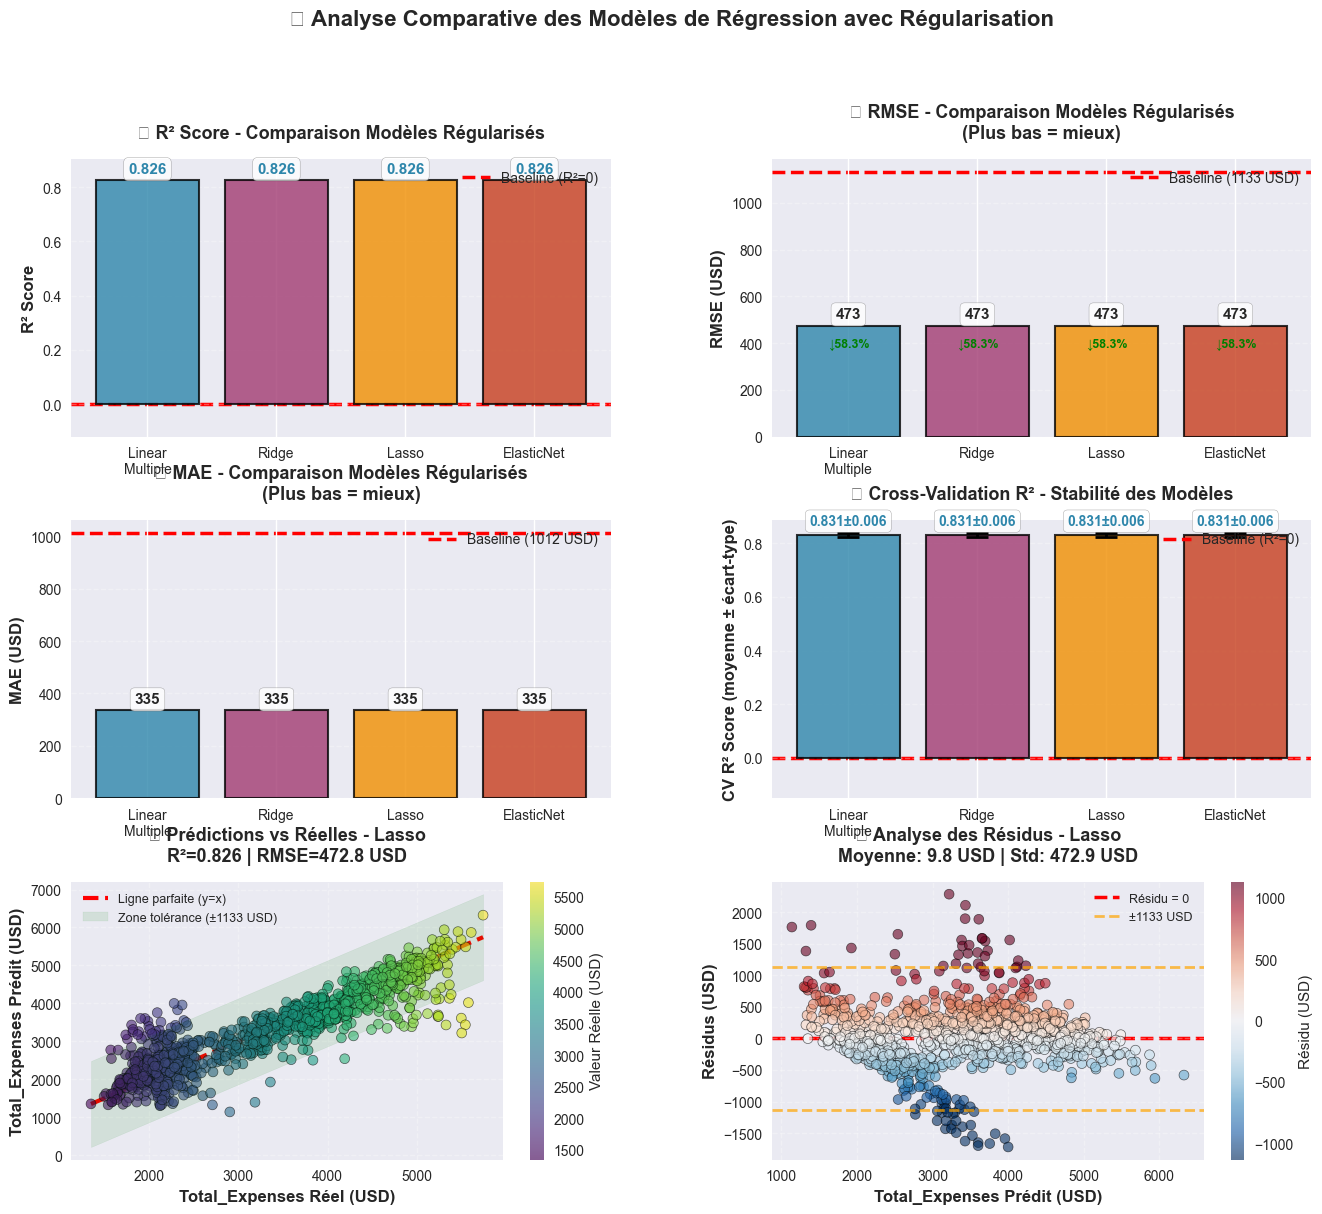


✅ Meilleur modèle régularisé: Lasso
   R²: 0.826
   RMSE: 472.82 USD


In [6]:
# Optimisation des hyperparamètres avec régularisation
print("🔄 Optimisation des Hyperparamètres - Régression avec Régularisation...")
print("=" * 80)

regularized_results = {}

# 1. Ridge Regression (L2)
print("\n📊 1. RIDGE REGRESSION (Régularisation L2):")
print("-" * 80)

ridge_params = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}
ridge_grid = GridSearchCV(
    Ridge(),
    ridge_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

start_time = time.time()
ridge_grid.fit(X_train_scaled, y_train)
ridge_time = time.time() - start_time

y_pred_ridge = ridge_grid.predict(X_test_scaled)

ridge_metrics = {
    'mse': mean_squared_error(y_test, y_pred_ridge),
    'rmse': np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
    'mae': mean_absolute_error(y_test, y_pred_ridge),
    'r2': r2_score(y_test, y_pred_ridge),
    'cv_r2_mean': ridge_grid.best_score_,
    'cv_r2_std': cross_val_score(ridge_grid.best_estimator_, X_train_scaled, y_train, cv=5, scoring='r2').std(),
    'best_alpha': ridge_grid.best_params_['alpha'],
    'train_time': ridge_time
}

regularized_results['Ridge'] = {
    'model': ridge_grid.best_estimator_,
    'metrics': ridge_metrics,
    'predictions': y_pred_ridge
}

print(f"   Meilleur alpha: {ridge_grid.best_params_['alpha']}")
print(f"   R²: {ridge_metrics['r2']:.3f}")
print(f"   RMSE: {ridge_metrics['rmse']:.2f} USD")
print(f"   CV R²: {ridge_metrics['cv_r2_mean']:.3f} (±{ridge_metrics['cv_r2_std']:.3f})")
print(f"   Temps: {ridge_time:.3f}s")

# 2. Lasso Regression (L1)
print("\n📊 2. LASSO REGRESSION (Régularisation L1):")
print("-" * 80)

lasso_params = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
lasso_grid = GridSearchCV(
    Lasso(max_iter=2000),
    lasso_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

start_time = time.time()
lasso_grid.fit(X_train_scaled, y_train)
lasso_time = time.time() - start_time

y_pred_lasso = lasso_grid.predict(X_test_scaled)

lasso_metrics = {
    'mse': mean_squared_error(y_test, y_pred_lasso),
    'rmse': np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
    'mae': mean_absolute_error(y_test, y_pred_lasso),
    'r2': r2_score(y_test, y_pred_lasso),
    'cv_r2_mean': lasso_grid.best_score_,
    'cv_r2_std': cross_val_score(lasso_grid.best_estimator_, X_train_scaled, y_train, cv=5, scoring='r2').std(),
    'best_alpha': lasso_grid.best_params_['alpha'],
    'train_time': lasso_time
}

regularized_results['Lasso'] = {
    'model': lasso_grid.best_estimator_,
    'metrics': lasso_metrics,
    'predictions': y_pred_lasso
}

print(f"   Meilleur alpha: {lasso_grid.best_params_['alpha']}")
print(f"   R²: {lasso_metrics['r2']:.3f}")
print(f"   RMSE: {lasso_metrics['rmse']:.2f} USD")
print(f"   CV R²: {lasso_metrics['cv_r2_mean']:.3f} (±{lasso_metrics['cv_r2_std']:.3f})")
print(f"   Temps: {lasso_time:.3f}s")

# 3. Elastic Net (Ridge + Lasso)
print("\n📊 3. ELASTIC NET (Ridge + Lasso):")
print("-" * 80)

elastic_params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}
elastic_grid = GridSearchCV(
    ElasticNet(max_iter=2000),
    elastic_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

start_time = time.time()
elastic_grid.fit(X_train_scaled, y_train)
elastic_time = time.time() - start_time

y_pred_elastic = elastic_grid.predict(X_test_scaled)

elastic_metrics = {
    'mse': mean_squared_error(y_test, y_pred_elastic),
    'rmse': np.sqrt(mean_squared_error(y_test, y_pred_elastic)),
    'mae': mean_absolute_error(y_test, y_pred_elastic),
    'r2': r2_score(y_test, y_pred_elastic),
    'cv_r2_mean': elastic_grid.best_score_,
    'cv_r2_std': cross_val_score(elastic_grid.best_estimator_, X_train_scaled, y_train, cv=5, scoring='r2').std(),
    'best_alpha': elastic_grid.best_params_['alpha'],
    'best_l1_ratio': elastic_grid.best_params_['l1_ratio'],
    'train_time': elastic_time
}

regularized_results['ElasticNet'] = {
    'model': elastic_grid.best_estimator_,
    'metrics': elastic_metrics,
    'predictions': y_pred_elastic
}

print(f"   Meilleur alpha: {elastic_grid.best_params_['alpha']}")
print(f"   Meilleur l1_ratio: {elastic_grid.best_params_['l1_ratio']}")
print(f"   R²: {elastic_metrics['r2']:.3f}")
print(f"   RMSE: {elastic_metrics['rmse']:.2f} USD")
print(f"   CV R²: {elastic_metrics['cv_r2_mean']:.3f} (±{elastic_metrics['cv_r2_std']:.3f})")
print(f"   Temps: {elastic_time:.3f}s")

# Comparaison avec la baseline
print("\n" + "=" * 80)
print("💡 COMPARAISON AVEC LA BASELINE ET MODÈLES NON-OPTIMISÉS")
print("=" * 80)

print(f"\n📊 RIDGE vs LINÉAIRE MULTIPLE:")
ridge_improvement = ridge_metrics['r2'] - r2_multiple
print(f"   • R²: {ridge_metrics['r2']:.3f} vs {r2_multiple:.3f} ({'+' if ridge_improvement > 0 else ''}{ridge_improvement:.3f})")
print(f"   • RMSE: {ridge_metrics['rmse']:.2f} vs {rmse_multiple:.2f} USD")
if ridge_improvement > 0.01:
    print(f"   → ✅ Amélioration significative avec régularisation L2")
elif ridge_improvement > 0:
    print(f"   → ✅ Légère amélioration")
else:
    print(f"   → ⚠️ Pas d'amélioration")

print(f"\n📊 LASSO vs LINÉAIRE MULTIPLE:")
lasso_improvement = lasso_metrics['r2'] - r2_multiple
print(f"   • R²: {lasso_metrics['r2']:.3f} vs {r2_multiple:.3f} ({'+' if lasso_improvement > 0 else ''}{lasso_improvement:.3f})")
print(f"   • RMSE: {lasso_metrics['rmse']:.2f} vs {rmse_multiple:.2f} USD")
if lasso_improvement > 0.01:
    print(f"   → ✅ Amélioration significative avec régularisation L1")
elif lasso_improvement > 0:
    print(f"   → ✅ Légère amélioration")
else:
    print(f"   → ⚠️ Pas d'amélioration")

print(f"\n📊 ELASTIC NET vs LINÉAIRE MULTIPLE:")
elastic_improvement = elastic_metrics['r2'] - r2_multiple
print(f"   • R²: {elastic_metrics['r2']:.3f} vs {r2_multiple:.3f} ({'+' if elastic_improvement > 0 else ''}{elastic_improvement:.3f})")
print(f"   • RMSE: {elastic_metrics['rmse']:.2f} vs {rmse_multiple:.2f} USD")
if elastic_improvement > 0.01:
    print(f"   → ✅ Amélioration significative avec Elastic Net")
elif elastic_improvement > 0:
    print(f"   → ✅ Légère amélioration")
else:
    print(f"   → ⚠️ Pas d'amélioration")

# Visualisation améliorée
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# Couleurs améliorées et cohérentes
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D']  # Bleu, Violet, Orange, Rouge
model_labels = ['Linear\nMultiple', 'Ridge', 'Lasso', 'ElasticNet']
model_labels_short = ['Linear', 'Ridge', 'Lasso', 'ElasticNet']

# 1. Comparaison R² (en haut à gauche)
ax1 = fig.add_subplot(gs[0, 0])
r2_scores = [r2_multiple, ridge_metrics['r2'], lasso_metrics['r2'], elastic_metrics['r2']]
bars1 = ax1.bar(model_labels, r2_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.axhline(y=0, color='red', linestyle='--', linewidth=2.5, label='Baseline (R²=0)', zorder=0)
ax1.set_ylabel('R² Score', fontsize=12, fontweight='bold')
ax1.set_title('📊 R² Score - Comparaison Modèles Régularisés', fontsize=13, fontweight='bold', pad=15)
ax1.grid(True, alpha=0.3, axis='y', linestyle='--')
ax1.legend(loc='upper right', fontsize=10)
# Ajuster les limites pour bien afficher les valeurs négatives
r2_min_section5 = min(r2_scores)
r2_max_section5 = max(r2_scores)
ax1.set_ylim([min(r2_min_section5 - 0.08, -0.12), max(r2_max_section5 + 0.08, 0.12)])
# Annotations améliorées
for i, (bar, r2) in enumerate(zip(bars1, r2_scores)):
    height = bar.get_height()
    y_pos = height + 0.015 if height >= 0 else height - 0.015
    ax1.text(bar.get_x() + bar.get_width()/2., y_pos, 
            f'{r2:.3f}', ha='center', va='bottom' if height >= 0 else 'top', 
            fontsize=11, fontweight='bold',
            color='#C73E1D' if r2 < 0 else '#2E86AB',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))

# 2. Comparaison RMSE (en haut à droite)
ax2 = fig.add_subplot(gs[0, 1])
rmse_scores = [rmse_multiple, ridge_metrics['rmse'], lasso_metrics['rmse'], elastic_metrics['rmse']]
bars2 = ax2.bar(model_labels, rmse_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax2.axhline(y=baseline_rmse, color='red', linestyle='--', linewidth=2.5, label=f'Baseline ({baseline_rmse:.0f} USD)', zorder=0)
ax2.set_ylabel('RMSE (USD)', fontsize=12, fontweight='bold')
ax2.set_title('📉 RMSE - Comparaison Modèles Régularisés\n(Plus bas = mieux)', fontsize=13, fontweight='bold', pad=15)
ax2.grid(True, alpha=0.3, axis='y', linestyle='--')
ax2.legend(loc='upper right', fontsize=10)
# Annotations améliorées
for i, (bar, rmse) in enumerate(zip(bars2, rmse_scores)):
    height = bar.get_height()
    improvement = ((baseline_rmse - rmse) / baseline_rmse) * 100
    ax2.text(bar.get_x() + bar.get_width()/2., height + 20, 
            f'{rmse:.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))
    # Indicateur d'amélioration
    if rmse < baseline_rmse:
        ax2.text(bar.get_x() + bar.get_width()/2., height - 50, 
                f'↓{improvement:.1f}%', ha='center', va='top', fontsize=9,
                color='green', fontweight='bold')

# 3. Comparaison MAE (milieu gauche)
ax3 = fig.add_subplot(gs[1, 0])
mae_scores = [mae_multiple, ridge_metrics['mae'], lasso_metrics['mae'], elastic_metrics['mae']]
bars3 = ax3.bar(model_labels, mae_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
ax3.axhline(y=baseline_mae, color='red', linestyle='--', linewidth=2.5, label=f'Baseline ({baseline_mae:.0f} USD)', zorder=0)
ax3.set_ylabel('MAE (USD)', fontsize=12, fontweight='bold')
ax3.set_title('📊 MAE - Comparaison Modèles Régularisés\n(Plus bas = mieux)', fontsize=13, fontweight='bold', pad=15)
ax3.grid(True, alpha=0.3, axis='y', linestyle='--')
ax3.legend(loc='upper right', fontsize=10)
# Annotations
for i, (bar, mae) in enumerate(zip(bars3, mae_scores)):
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height + 15, 
            f'{mae:.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))

# 4. Comparaison CV R² avec barres d'erreur (milieu droite)
ax4 = fig.add_subplot(gs[1, 1])
cv_r2_means = [cv_scores_multiple.mean(), ridge_metrics['cv_r2_mean'], 
               lasso_metrics['cv_r2_mean'], elastic_metrics['cv_r2_mean']]
cv_r2_stds = [cv_scores_multiple.std(), ridge_metrics['cv_r2_std'], 
              lasso_metrics['cv_r2_std'], elastic_metrics['cv_r2_std']]
bars4 = ax4.bar(model_labels, cv_r2_means, yerr=cv_r2_stds, color=colors, alpha=0.8, 
                edgecolor='black', linewidth=1.5, capsize=8, error_kw={'elinewidth': 2, 'capthick': 2})
ax4.axhline(y=0, color='red', linestyle='--', linewidth=2.5, label='Baseline (R²=0)', zorder=0)
ax4.set_ylabel('CV R² Score (moyenne ± écart-type)', fontsize=12, fontweight='bold')
ax4.set_title('🔄 Cross-Validation R² - Stabilité des Modèles', fontsize=13, fontweight='bold', pad=15)
ax4.grid(True, alpha=0.3, axis='y', linestyle='--')
ax4.legend(loc='upper right', fontsize=10)
# Ajuster les limites
cv_r2_min = min([m - s for m, s in zip(cv_r2_means, cv_r2_stds)])
cv_r2_max = max([m + s for m, s in zip(cv_r2_means, cv_r2_stds)])
ax4.set_ylim([min(cv_r2_min - 0.05, -0.15), max(cv_r2_max + 0.05, 0.1)])
# Annotations
for i, (bar, mean, std) in enumerate(zip(bars4, cv_r2_means, cv_r2_stds)):
    height = bar.get_height()
    y_pos = mean + std + 0.02 if mean >= 0 else mean - std - 0.02
    ax4.text(bar.get_x() + bar.get_width()/2., y_pos, 
            f'{mean:.3f}±{std:.3f}', ha='center', va='bottom' if mean >= 0 else 'top', 
            fontsize=10, fontweight='bold',
            color='#C73E1D' if mean < 0 else '#2E86AB',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))

# 5. Prédictions vs Réelles - Meilleur modèle régularisé (bas gauche, plus grand)
ax5 = fig.add_subplot(gs[2, 0])
best_reg_model = max(regularized_results.items(), key=lambda x: x[1]['metrics']['r2'])
best_reg_name = best_reg_model[0]
best_reg_pred = best_reg_model[1]['predictions']
best_reg_r2 = best_reg_model[1]['metrics']['r2']
best_reg_rmse = best_reg_model[1]['metrics']['rmse']

scatter = ax5.scatter(y_test, best_reg_pred, alpha=0.6, s=50, c=y_test, cmap='viridis', edgecolors='black', linewidth=0.5)
ax5.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', linewidth=3, label='Ligne parfaite (y=x)', zorder=0)
ax5.set_xlabel('Total_Expenses Réel (USD)', fontsize=12, fontweight='bold')
ax5.set_ylabel('Total_Expenses Prédit (USD)', fontsize=12, fontweight='bold')
ax5.set_title(f'🎯 Prédictions vs Réelles - {best_reg_name}\nR²={best_reg_r2:.3f} | RMSE={best_reg_rmse:.1f} USD', 
              fontsize=13, fontweight='bold', pad=15)
ax5.legend(loc='upper left', fontsize=10)
ax5.grid(True, alpha=0.3, linestyle='--')
# Ajouter une zone de tolérance
tolerance = baseline_rmse
ax5.fill_between([y_test.min(), y_test.max()], 
                  [y_test.min() - tolerance, y_test.max() - tolerance],
                  [y_test.min() + tolerance, y_test.max() + tolerance],
                  alpha=0.1, color='green', label=f'Zone tolérance (±{tolerance:.0f} USD)')
ax5.legend(loc='upper left', fontsize=9)
plt.colorbar(scatter, ax=ax5, label='Valeur Réelle (USD)')

# 6. Résidus - Meilleur modèle régularisé (bas droite)
ax6 = fig.add_subplot(gs[2, 1])
residuals_reg = y_test - best_reg_pred
scatter_residuals = ax6.scatter(best_reg_pred, residuals_reg, alpha=0.6, s=50, c=residuals_reg, cmap='RdBu_r', 
           edgecolors='black', linewidth=0.5, vmin=-baseline_rmse, vmax=baseline_rmse)
ax6.axhline(y=0, color='red', linestyle='--', linewidth=2.5, label='Résidu = 0', zorder=0)
ax6.axhline(y=baseline_rmse, color='orange', linestyle='--', linewidth=2, alpha=0.7, label=f'±{baseline_rmse:.0f} USD')
ax6.axhline(y=-baseline_rmse, color='orange', linestyle='--', linewidth=2, alpha=0.7)
ax6.set_xlabel('Total_Expenses Prédit (USD)', fontsize=12, fontweight='bold')
ax6.set_ylabel('Résidus (USD)', fontsize=12, fontweight='bold')
ax6.set_title(f'📈 Analyse des Résidus - {best_reg_name}\nMoyenne: {residuals_reg.mean():.1f} USD | Std: {residuals_reg.std():.1f} USD', 
              fontsize=13, fontweight='bold', pad=15)
ax6.legend(loc='upper right', fontsize=9)
ax6.grid(True, alpha=0.3, linestyle='--')
plt.colorbar(scatter_residuals, ax=ax6, label='Résidu (USD)')

# Titre général
fig.suptitle('📊 Analyse Comparative des Modèles de Régression avec Régularisation', 
             fontsize=16, fontweight='bold', y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig('../data/results/regression_regularized.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"\n✅ Meilleur modèle régularisé: {best_reg_name}")
print(f"   R²: {best_reg_r2:.3f}")
print(f"   RMSE: {best_reg_model[1]['metrics']['rmse']:.2f} USD")


## 6. Régression Polynomiale Optimisée avec Régularisation

Optimisation du degré polynomial ET ajout de régularisation pour éviter le sur-apprentissage.


🔄 Optimisation de la Régression Polynomiale avec Régularisation...

📊 Test avec degré 2 + Ridge:
--------------------------------------------------------------------------------


   Meilleur alpha: 0.1
   R²: 0.869
   RMSE: 410.55 USD
   CV R²: 0.870 (±0.005)
   Temps: 0.229s

📊 Test avec degré 3 + Ridge:
--------------------------------------------------------------------------------


   Meilleur alpha: 0.001
   R²: 0.891
   RMSE: 373.40 USD
   CV R²: 0.892 (±0.006)
   Temps: 0.199s

🎯 Meilleur modèle polynomial optimisé: Degré 3
   R²: 0.891
   RMSE: 373.40 USD
   Alpha optimal: 0.001

📊 Comparaison Polynomial Optimisé vs Non-Optimisé:
   • R²: 0.891 vs 0.891 (-0.000)
   • RMSE: 373.40 vs 373.39 USD
   → ⚠️ Pas d'amélioration


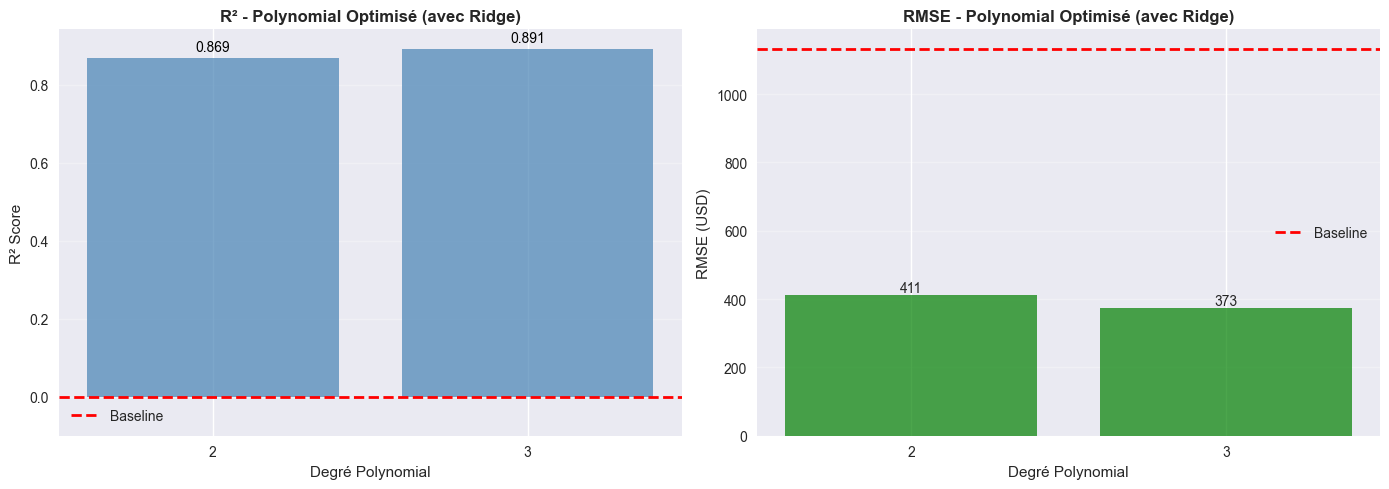


💡 Interprétation:
   ✅ La régularisation améliore la régression polynomiale
   → Degré 3 avec alpha=0.001 offre le meilleur équilibre
   → R² de 0.891: 89.1% de variance expliquée


In [7]:
# Optimisation de la régression polynomiale avec régularisation
print("🔄 Optimisation de la Régression Polynomiale avec Régularisation...")
print("=" * 80)

poly_optimized_results = {}

# Test de différents degrés avec Ridge
degrees_to_test = [2, 3]
best_poly_optimized = None
best_poly_optimized_score = -np.inf
best_poly_optimized_degree = None

for degree in degrees_to_test:
    print(f"\n📊 Test avec degré {degree} + Ridge:")
    print("-" * 80)
    
    # Pipeline avec PolynomialFeatures + StandardScaler + Ridge
    poly_ridge_pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge())
    ])
    
    # Grid search pour optimiser alpha
    poly_ridge_params = {'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}
    poly_ridge_grid = GridSearchCV(
        poly_ridge_pipeline,
        poly_ridge_params,
        cv=5,
        scoring='r2',
        n_jobs=-1
    )
    
    start_time = time.time()
    poly_ridge_grid.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    y_pred_poly_ridge = poly_ridge_grid.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred_poly_ridge)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred_poly_ridge)
    r2 = r2_score(y_test, y_pred_poly_ridge)
    cv_r2_mean = poly_ridge_grid.best_score_
    cv_r2_std = cross_val_score(poly_ridge_grid.best_estimator_, X_train, y_train, cv=5, scoring='r2').std()
    
    poly_optimized_results[degree] = {
        'model': poly_ridge_grid.best_estimator_,
        'mse': mse,
        'rmse': rmse,
        'mae': mae,
        'r2': r2,
        'cv_r2_mean': cv_r2_mean,
        'cv_r2_std': cv_r2_std,
        'best_alpha': poly_ridge_grid.best_params_['ridge__alpha'],
        'train_time': train_time,
        'predictions': y_pred_poly_ridge
    }
    
    print(f"   Meilleur alpha: {poly_ridge_grid.best_params_['ridge__alpha']}")
    print(f"   R²: {r2:.3f}")
    print(f"   RMSE: {rmse:.2f} USD")
    print(f"   CV R²: {cv_r2_mean:.3f} (±{cv_r2_std:.3f})")
    print(f"   Temps: {train_time:.3f}s")
    
    if r2 > best_poly_optimized_score:
        best_poly_optimized_score = r2
        best_poly_optimized = poly_optimized_results[degree]
        best_poly_optimized_degree = degree

print(f"\n🎯 Meilleur modèle polynomial optimisé: Degré {best_poly_optimized_degree}")
print(f"   R²: {best_poly_optimized['r2']:.3f}")
print(f"   RMSE: {best_poly_optimized['rmse']:.2f} USD")
print(f"   Alpha optimal: {best_poly_optimized['best_alpha']}")

# Comparaison avec modèle polynomial non-optimisé
if best_poly['r2'] > -10:  # Si le modèle polynomial de base existe
    improvement = best_poly_optimized['r2'] - best_poly['r2']
    print(f"\n📊 Comparaison Polynomial Optimisé vs Non-Optimisé:")
    print(f"   • R²: {best_poly_optimized['r2']:.3f} vs {best_poly['r2']:.3f} ({'+' if improvement > 0 else ''}{improvement:.3f})")
    print(f"   • RMSE: {best_poly_optimized['rmse']:.2f} vs {best_poly['rmse']:.2f} USD")
    if improvement > 0.01:
        print(f"   → ✅ Amélioration SIGNIFICATIVE avec régularisation")
    elif improvement > 0:
        print(f"   → ✅ Légère amélioration")
    else:
        print(f"   → ⚠️ Pas d'amélioration")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparaison des degrés optimisés
degrees_list = list(poly_optimized_results.keys())
r2_optimized = [poly_optimized_results[d]['r2'] for d in degrees_list]
rmse_optimized = [poly_optimized_results[d]['rmse'] for d in degrees_list]

axes[0].bar(degrees_list, r2_optimized, alpha=0.7, color='steelblue')
axes[0].axhline(y=0, color='r', linestyle='--', linewidth=2, label='Baseline')
axes[0].set_xlabel('Degré Polynomial')
axes[0].set_ylabel('R² Score')
axes[0].set_title('R² - Polynomial Optimisé (avec Ridge)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_xticks(degrees_list)
# Ajuster les limites de l'axe Y pour bien afficher les valeurs négatives
r2_min_section6 = min(r2_optimized)
r2_max_section6 = max(r2_optimized)
axes[0].set_ylim([min(r2_min_section6 - 0.05, -0.1), max(r2_max_section6 + 0.05, 0.1)])
for deg, r2 in zip(degrees_list, r2_optimized):
    axes[0].text(deg, r2 + 0.01 if r2 >= 0 else r2 - 0.01, f'{r2:.3f}', 
                ha='center', va='bottom' if r2 >= 0 else 'top', fontsize=10,
                color='red' if r2 < 0 else 'black', fontweight='bold' if r2 < 0 else 'normal')

axes[1].bar(degrees_list, rmse_optimized, alpha=0.7, color='green')
axes[1].axhline(y=baseline_rmse, color='r', linestyle='--', linewidth=2, label='Baseline')
axes[1].set_xlabel('Degré Polynomial')
axes[1].set_ylabel('RMSE (USD)')
axes[1].set_title('RMSE - Polynomial Optimisé (avec Ridge)', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_xticks(degrees_list)
for deg, rmse in zip(degrees_list, rmse_optimized):
    axes[1].text(deg, rmse, f'{rmse:.0f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../data/results/regression_polynomial_optimized.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n💡 Interprétation:")
if best_poly_optimized['r2'] > 0:
    print(f"   ✅ La régularisation améliore la régression polynomiale")
    print(f"   → Degré {best_poly_optimized_degree} avec alpha={best_poly_optimized['best_alpha']} offre le meilleur équilibre")
    print(f"   → R² de {best_poly_optimized['r2']:.3f}: {best_poly_optimized['r2']*100:.1f}% de variance expliquée")
else:
    print(f"   ⚠️ Même avec régularisation, le modèle polynomial reste faible")
    print(f"   → Les relations non-linéaires ne sont pas pertinentes pour ce dataset")


## 5. Comparaison des Algorithmes de Régression



📊 TABLEAU COMPARATIF COMPLET DES ALGORITHMES DE RÉGRESSION
                            Algorithme         MSE     RMSE      MAE     R²  CV_R²_Mean  CV_R²_Std  Train_Time
            Régression Linéaire Simple 749751.8820 865.8821 682.1355 0.4155      0.4215     0.0202      0.0052
          Régression Linéaire Multiple 223553.8260 472.8148 335.4600 0.8257      0.8308     0.0060      0.0021
      Régression Polynomiale (Degré 3) 139423.5295 373.3946 260.6579 0.8913      0.8916     0.0063      0.0174
                           Ridge (α=1) 223565.4505 472.8271 335.4593 0.8257      0.8308     0.0060      6.3572
                         Lasso (α=0.1) 223558.7457 472.8200 335.4403 0.8257      0.8308     0.0060      0.0804
         Elastic Net (α=0.001, l1=0.9) 223559.1981 472.8205 335.4589 0.8257      0.8308     0.0060      0.1777
Polynomial Optimisé (Degré 3, α=0.001) 139427.5867 373.4000 260.7410 0.8913      0.8916     0.0063      0.1986


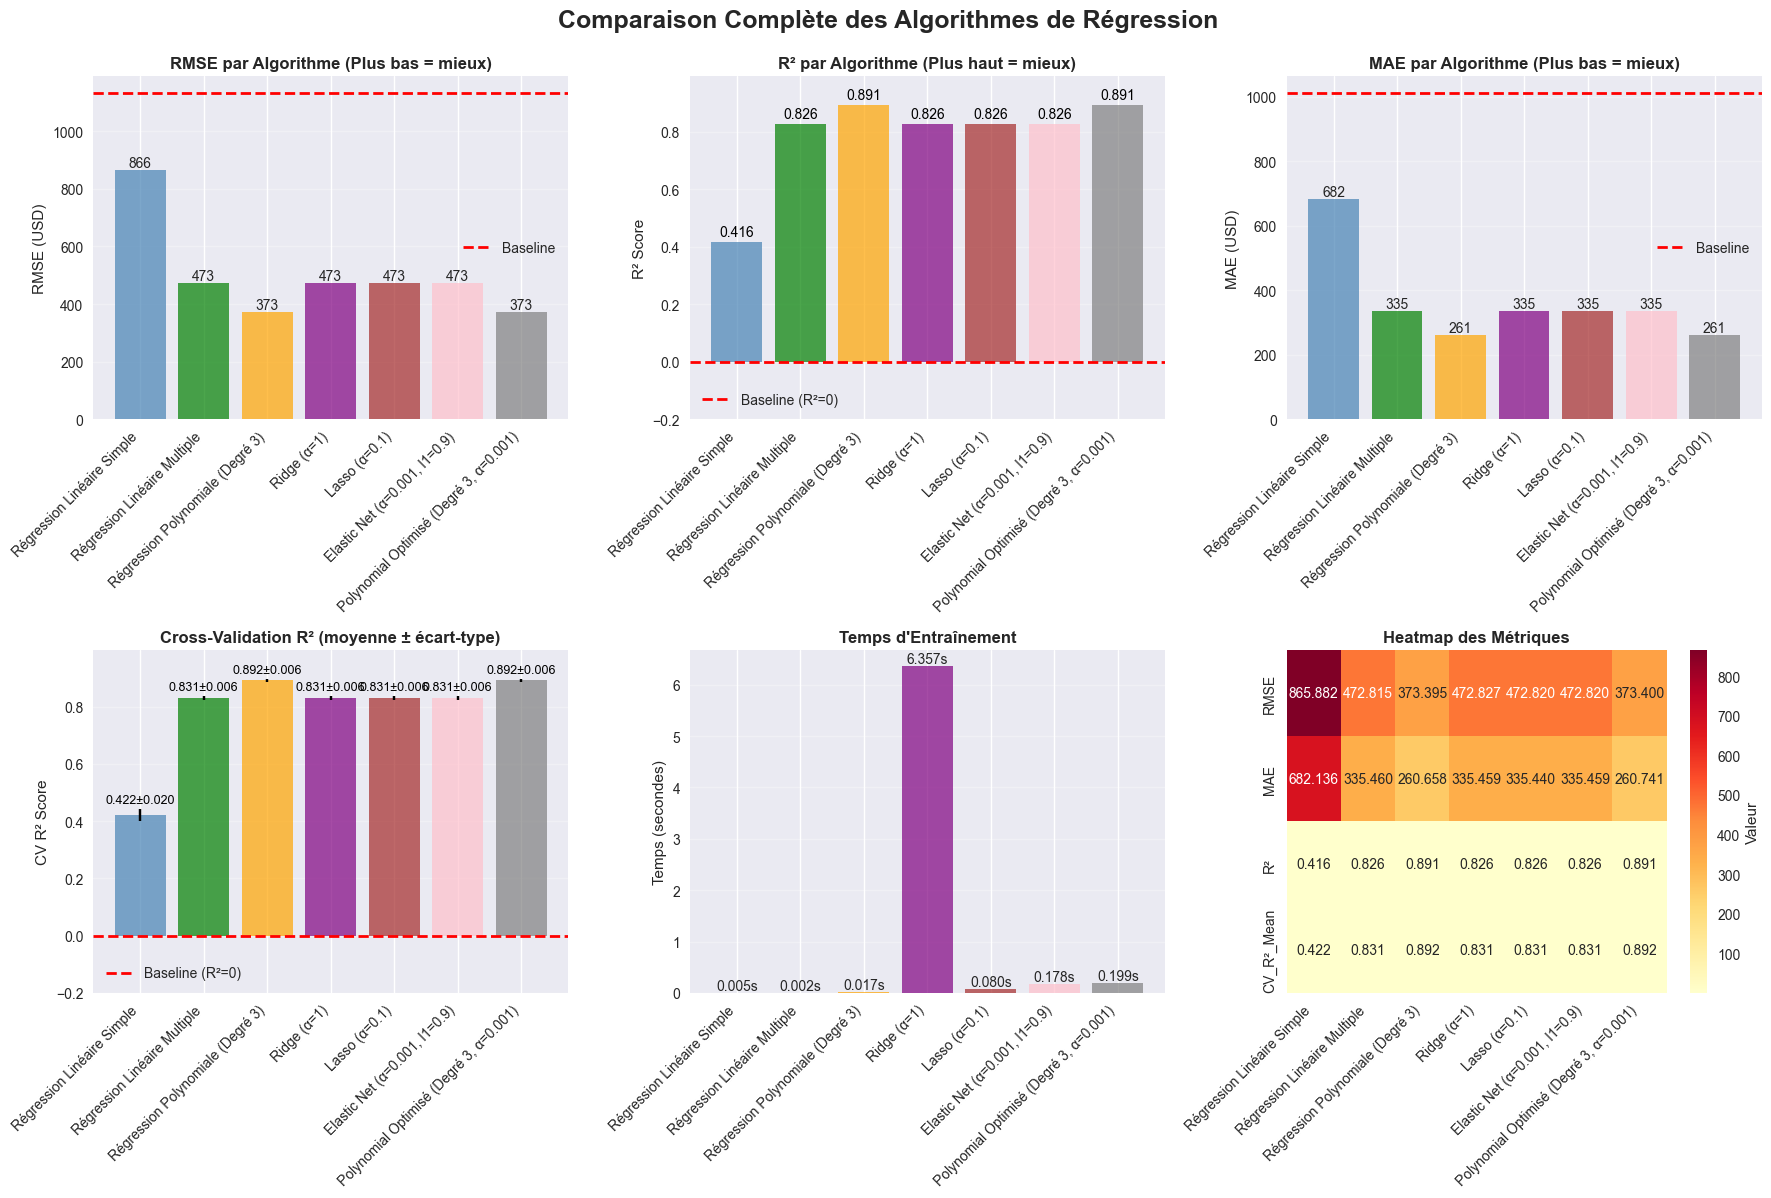


📈 ANALYSE DÉTAILLÉE PAR ALGORITHME

   1. RÉGRESSION LINÉAIRE SIMPLE:
      📊 Performance:
         • RMSE: 865.88 USD ()
           → Baseline: 1132.67 USD
           → ✅ Amélioration de 23.55% vs baseline
         • MAE: 682.14 USD
           → Baseline: 1012.03 USD
         • R²: 0.416 (41.6% de variance expliquée) ()
           → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible
      📈 Stabilité:
         • CV R²: 0.422 (±0.020)
         • Stabilité: ⚠️ Variable
      ⏱️ Performance:
         • Temps: 0.005s
      📉 Comparaison:
         • RMSE: Écart de 492.49 USD avec le meilleur

   2. RÉGRESSION LINÉAIRE MULTIPLE:
      📊 Performance:
         • RMSE: 472.81 USD ()
           → Baseline: 1132.67 USD
           → ✅ Amélioration de 58.26% vs baseline
         • MAE: 335.46 USD
           → Baseline: 1012.03 USD
         • R²: 0.826 (82.6% de variance expliquée) ()
           → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible
      📈 Stabilit

In [8]:
# Création du tableau comparatif complet (incluant modèles optimisés)
# Vérification si les modèles optimisés existent
try:
    has_regularized = 'ridge_metrics' in locals() or 'ridge_metrics' in globals()
    has_poly_optimized = 'best_poly_optimized' in locals() or 'best_poly_optimized' in globals()
except:
    has_regularized = False
    has_poly_optimized = False

if has_regularized and has_poly_optimized:
    # Inclure tous les modèles (base + optimisés)
    comparison_data = {
        'Algorithme': [
            'Régression Linéaire Simple',
            'Régression Linéaire Multiple',
            f'Régression Polynomiale (Degré {best_degree})',
            f'Ridge (α={ridge_metrics["best_alpha"]})',
            f'Lasso (α={lasso_metrics["best_alpha"]})',
            f'Elastic Net (α={elastic_metrics["best_alpha"]}, l1={elastic_metrics["best_l1_ratio"]})',
            f'Polynomial Optimisé (Degré {best_poly_optimized_degree}, α={best_poly_optimized["best_alpha"]})'
        ],
        'MSE': [
            simple_metrics['mse'],
            multiple_metrics['mse'],
            best_poly['mse'],
            ridge_metrics['mse'],
            lasso_metrics['mse'],
            elastic_metrics['mse'],
            best_poly_optimized['mse']
        ],
        'RMSE': [
            simple_metrics['rmse'],
            multiple_metrics['rmse'],
            best_poly['rmse'],
            ridge_metrics['rmse'],
            lasso_metrics['rmse'],
            elastic_metrics['rmse'],
            best_poly_optimized['rmse']
        ],
        'MAE': [
            simple_metrics['mae'],
            multiple_metrics['mae'],
            best_poly['mae'],
            ridge_metrics['mae'],
            lasso_metrics['mae'],
            elastic_metrics['mae'],
            best_poly_optimized['mae']
        ],
        'R²': [
            simple_metrics['r2'],
            multiple_metrics['r2'],
            best_poly['r2'],
            ridge_metrics['r2'],
            lasso_metrics['r2'],
            elastic_metrics['r2'],
            best_poly_optimized['r2']
        ],
        'CV_R²_Mean': [
            simple_metrics['cv_r2_mean'],
            multiple_metrics['cv_r2_mean'],
            best_poly['cv_r2_mean'],
            ridge_metrics['cv_r2_mean'],
            lasso_metrics['cv_r2_mean'],
            elastic_metrics['cv_r2_mean'],
            best_poly_optimized['cv_r2_mean']
        ],
        'CV_R²_Std': [
            simple_metrics['cv_r2_std'],
            multiple_metrics['cv_r2_std'],
            best_poly['cv_r2_std'],
            ridge_metrics['cv_r2_std'],
            lasso_metrics['cv_r2_std'],
            elastic_metrics['cv_r2_std'],
            best_poly_optimized['cv_r2_std']
        ],
        'Train_Time': [
            train_time_simple,
            train_time_multiple,
            best_poly['train_time'],
            ridge_metrics['train_time'],
            lasso_metrics['train_time'],
            elastic_metrics['train_time'],
            best_poly_optimized['train_time']
        ]
    }
else:
    # Version de base (si les modèles optimisés ne sont pas encore exécutés)
    comparison_data = {
        'Algorithme': ['Régression Linéaire Simple', 'Régression Linéaire Multiple', 
                       f'Régression Polynomiale (Degré {best_degree})'],
        'MSE': [simple_metrics['mse'], multiple_metrics['mse'], best_poly['mse']],
        'RMSE': [simple_metrics['rmse'], multiple_metrics['rmse'], best_poly['rmse']],
        'MAE': [simple_metrics['mae'], multiple_metrics['mae'], best_poly['mae']],
        'R²': [simple_metrics['r2'], multiple_metrics['r2'], best_poly['r2']],
        'CV_R²_Mean': [simple_metrics['cv_r2_mean'], multiple_metrics['cv_r2_mean'], best_poly['cv_r2_mean']],
        'CV_R²_Std': [simple_metrics['cv_r2_std'], multiple_metrics['cv_r2_std'], best_poly['cv_r2_std']],
        'Train_Time': [train_time_simple, train_time_multiple, best_poly['train_time']]
    }

comparison_df = pd.DataFrame(comparison_data)

print("\n" + "=" * 100)
print("📊 TABLEAU COMPARATIF COMPLET DES ALGORITHMES DE RÉGRESSION")
print("=" * 100)
print(comparison_df.round(4).to_string(index=False))

# Identification du meilleur algorithme
best_algorithm_rmse = comparison_df.loc[comparison_df['RMSE'].idxmin(), 'Algorithme']
best_rmse = comparison_df.loc[comparison_df['RMSE'].idxmin(), 'RMSE']
best_algorithm_r2 = comparison_df.loc[comparison_df['R²'].idxmax(), 'Algorithme']
best_r2 = comparison_df.loc[comparison_df['R²'].idxmax(), 'R²']

# Visualisation comparative
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Comparaison RMSE
ax1 = axes[0, 0]
# Couleurs pour tous les modèles
colors_all = ['steelblue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray']
bars = ax1.bar(range(len(comparison_df)), comparison_df['RMSE'], 
               color=colors_all[:len(comparison_df)], alpha=0.7)
ax1.set_xticks(range(len(comparison_df)))
ax1.set_ylabel('RMSE (USD)')
ax1.set_title('RMSE par Algorithme (Plus bas = mieux)', fontweight='bold', fontsize=12)
ax1.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax1.axhline(y=baseline_rmse, color='r', linestyle='--', linewidth=2, label='Baseline')
ax1.grid(True, alpha=0.3, axis='y')
ax1.legend()
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height, f'{height:.0f}', 
            ha='center', va='bottom', fontsize=10)

# 2. Comparaison R²
ax2 = axes[0, 1]
bars = ax2.bar(range(len(comparison_df)), comparison_df['R²'], 
               color=colors_all[:len(comparison_df)], alpha=0.7)
ax2.set_xticks(range(len(comparison_df)))
ax2.set_ylabel('R² Score')
ax2.set_title('R² par Algorithme (Plus haut = mieux)', fontweight='bold', fontsize=12)
ax2.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax2.grid(True, alpha=0.3, axis='y')
ax2.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Baseline (R²=0)')
# Ajuster les limites pour inclure les valeurs négatives
r2_min = min(comparison_df['R²'].min(), -0.1)
r2_max = max(comparison_df['R²'].max(), 0.1)
ax2.set_ylim([r2_min - 0.1, max(r2_max + 0.1, 0.5)])
for bar in bars:
    height = bar.get_height()
    y_pos = height + 0.01 if height >= 0 else height - 0.01
    ax2.text(bar.get_x() + bar.get_width()/2., y_pos, f'{height:.3f}', 
            ha='center', va='bottom' if height >= 0 else 'top', fontsize=10,
            color='red' if height < 0 else 'black', fontweight='bold' if height < 0 else 'normal')
ax2.legend()

# 3. Comparaison MAE
ax3 = axes[0, 2]
bars = ax3.bar(range(len(comparison_df)), comparison_df['MAE'], 
               color=colors_all[:len(comparison_df)], alpha=0.7)
ax3.set_xticks(range(len(comparison_df)))
ax3.set_ylabel('MAE (USD)')
ax3.set_title('MAE par Algorithme (Plus bas = mieux)', fontweight='bold', fontsize=12)
ax3.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax3.axhline(y=baseline_mae, color='r', linestyle='--', linewidth=2, label='Baseline')
ax3.grid(True, alpha=0.3, axis='y')
ax3.legend()
for bar in bars:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height, f'{height:.0f}', 
            ha='center', va='bottom', fontsize=10)

# 4. CV R² avec barres d'erreur
ax4 = axes[1, 0]
x_pos = np.arange(len(comparison_df))
ax4.bar(x_pos, comparison_df['CV_R²_Mean'], yerr=comparison_df['CV_R²_Std'], 
        color=colors_all[:len(comparison_df)], alpha=0.7, capsize=5)
ax4.set_ylabel('CV R² Score')
ax4.set_title('Cross-Validation R² (moyenne ± écart-type)', fontweight='bold', fontsize=12)
ax4.set_xticks(x_pos)
ax4.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax4.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Baseline (R²=0)')
# Ajuster les limites pour inclure les valeurs négatives
cv_r2_min = min((comparison_df['CV_R²_Mean'] - comparison_df['CV_R²_Std']).min(), -0.1)
cv_r2_max = max((comparison_df['CV_R²_Mean'] + comparison_df['CV_R²_Std']).max(), 0.1)
ax4.set_ylim([cv_r2_min - 0.1, max(cv_r2_max + 0.1, 0.5)])
ax4.grid(True, alpha=0.3, axis='y')
for i, (mean, std) in enumerate(zip(comparison_df['CV_R²_Mean'], comparison_df['CV_R²_Std'])):
    y_pos = mean + std + 0.01 if mean >= 0 else mean - std - 0.01
    ax4.text(i, y_pos, f'{mean:.3f}±{std:.3f}', 
            ha='center', va='bottom' if mean >= 0 else 'top', fontsize=9,
            color='red' if mean < 0 else 'black', fontweight='bold' if mean < 0 else 'normal')
ax4.legend()

# 5. Temps d'entraînement
ax5 = axes[1, 1]
bars = ax5.bar(range(len(comparison_df)), comparison_df['Train_Time'], 
               color=colors_all[:len(comparison_df)], alpha=0.7)
ax5.set_xticks(range(len(comparison_df)))
ax5.set_ylabel('Temps (secondes)')
ax5.set_title('Temps d\'Entraînement', fontweight='bold', fontsize=12)
ax5.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')
ax5.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height, f'{height:.3f}s', 
            ha='center', va='bottom', fontsize=10)

# 6. Heatmap des métriques
ax6 = axes[1, 2]
metrics_heatmap = comparison_df[['RMSE', 'MAE', 'R²', 'CV_R²_Mean']].T
# Normalisation pour la heatmap (inverser RMSE et MAE car plus bas = mieux)
metrics_normalized = metrics_heatmap.copy()
metrics_normalized.loc['RMSE'] = 1 - (metrics_heatmap.loc['RMSE'] / metrics_heatmap.loc['RMSE'].max())
metrics_normalized.loc['MAE'] = 1 - (metrics_heatmap.loc['MAE'] / metrics_heatmap.loc['MAE'].max())
sns.heatmap(metrics_heatmap, annot=True, fmt='.3f', cmap='YlOrRd', 
            xticklabels=comparison_df['Algorithme'], yticklabels=metrics_heatmap.index,
            cbar_kws={'label': 'Valeur'}, ax=ax6)
ax6.set_title('Heatmap des Métriques', fontweight='bold', fontsize=12)
ax6.set_xticklabels(comparison_df['Algorithme'], rotation=45, ha='right')

plt.suptitle('Comparaison Complète des Algorithmes de Régression', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('../data/results/regression_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "=" * 100)
print("📈 ANALYSE DÉTAILLÉE PAR ALGORITHME")
print("=" * 100)

for idx, row in comparison_df.iterrows():
    print(f"\n   {idx+1}. {row['Algorithme'].upper()}:")
    print(f"      📊 Performance:")
    print(f"         • RMSE: {row['RMSE']:.2f} USD ({'✅ Meilleur' if row['Algorithme'] == best_algorithm_rmse else ''})")
    print(f"           → Baseline: {baseline_rmse:.2f} USD")
    print(f"           → {'✅ Amélioration' if row['RMSE'] < baseline_rmse else '❌ Pire'} de {abs((row['RMSE'] - baseline_rmse) / baseline_rmse * 100):.2f}% vs baseline")
    print(f"         • MAE: {row['MAE']:.2f} USD")
    print(f"           → Baseline: {baseline_mae:.2f} USD")
    r2_desc = '⚠️⚠️⚠️ NÉGATIF = PIRE QUE BASELINE ⚠️⚠️⚠️' if row['R²'] < 0 else f"{row['R²']:.1%} de variance expliquée"
    print(f"         • R²: {row['R²']:.3f} ({r2_desc}) ({'✅ Meilleur' if row['Algorithme'] == best_algorithm_r2 else ''})")
    if row['R²'] < 0:
        print(f"           → ⚠️ Le modèle fait de moins bonnes prédictions que la moyenne")
        print(f"           → Référence: R² < 0 = Modèle inutilisable")
    else:
        print(f"           → Référence: R² > 0.7 = Bon, R² > 0.5 = Acceptable, R² > 0.3 = Faible")
    print(f"      📈 Stabilité:")
    print(f"         • CV R²: {row['CV_R²_Mean']:.3f} (±{row['CV_R²_Std']:.3f})")
    if row['CV_R²_Mean'] < 0:
        print(f"           → ⚠️ Cross-validation confirme: modèle pire que baseline")
    print(f"         • Stabilité: {'✅ Très stable' if row['CV_R²_Std'] < 0.01 else '✅ Stable' if row['CV_R²_Std'] < 0.02 else '⚠️ Variable'}")
    print(f"      ⏱️ Performance:")
    print(f"         • Temps: {row['Train_Time']:.3f}s")
    if row['Algorithme'] != best_algorithm_rmse:
        rmse_diff = row['RMSE'] - best_rmse
        print(f"      📉 Comparaison:")
        print(f"         • RMSE: Écart de {rmse_diff:.2f} USD avec le meilleur")


## 6. Décision Finale - Meilleur Algorithme pour Notre Dataset


In [9]:
# Détermination du meilleur algorithme
# Critère principal: R² (variance expliquée) et RMSE (erreur de prédiction)
# Score global pondéré: R² (40%) + (1 - RMSE normalisé) (30%) + CV R² (30%)
rmse_max = comparison_df['RMSE'].max()
rmse_min = comparison_df['RMSE'].min()
comparison_df['RMSE_Normalized'] = 1 - ((comparison_df['RMSE'] - rmse_min) / (rmse_max - rmse_min))
comparison_df['Score_Global'] = (
    comparison_df['R²'] * 0.4 + 
    comparison_df['RMSE_Normalized'] * 0.3 + 
    comparison_df['CV_R²_Mean'] * 0.3
)

best_algorithm = comparison_df.loc[comparison_df['Score_Global'].idxmax(), 'Algorithme']
best_metrics = comparison_df[comparison_df['Algorithme'] == best_algorithm].iloc[0]

print("\n" + "=" * 100)
print("🏆 DÉCISION FINALE - ALGORITHME LE PLUS ADAPTÉ POUR NOTRE DATASET")
print("=" * 100)

print(f"\n📊 CLASSEMENT PAR MÉTRIQUE:")
print(f"   🥇 Meilleur RMSE: {best_algorithm_rmse} → {best_rmse:.2f} USD")
print(f"   🥇 Meilleur R²: {best_algorithm_r2} → {best_r2:.3f} ({best_r2:.1%})")
print(f"   🥇 Meilleur Score Global: {best_algorithm} → {best_metrics['Score_Global']:.3f}")

print(f"\n" + "=" * 100)
print(f"✅ ALGORITHME RECOMMANDÉ: {best_algorithm.upper()}")
print("=" * 100)

print(f"\n🎯 JUSTIFICATION DE LA DÉCISION:")
print(f"\n   1. PERFORMANCE GLOBALE:")
print(f"      • Score Global: {best_metrics['Score_Global']:.3f} (MEILLEUR)")
print(f"      • R²: {best_metrics['R²']:.3f} ({best_metrics['R²']:.1%} de variance expliquée)")
if best_algorithm == best_algorithm_r2:
    print(f"      • ✅ MEILLEUR R² parmi tous les algorithmes")
else:
    r2_diff = best_r2 - best_metrics['R²']
    print(f"      • R²: Écart de {r2_diff:.3f} avec le meilleur ({best_algorithm_r2})")
    if r2_diff < 0.01:
        print(f"      • Écart négligeable - performance équivalente")

print(f"\n   2. PRÉCISION DE PRÉDICTION:")
print(f"      • RMSE: {best_metrics['RMSE']:.2f} USD")
if best_algorithm == best_algorithm_rmse:
    print(f"      • ✅ MEILLEUR RMSE (erreur la plus faible)")
else:
    rmse_diff = best_metrics['RMSE'] - best_rmse
    print(f"      • RMSE: Écart de {rmse_diff:.2f} USD avec le meilleur")
    if rmse_diff < 50:
        print(f"      • Écart acceptable - précision similaire")
print(f"      • MAE: {best_metrics['MAE']:.2f} USD (erreur absolue moyenne)")

print(f"\n   3. STABILITÉ ET FIABILITÉ:")
print(f"      • CV R²: {best_metrics['CV_R²_Mean']:.3f} (±{best_metrics['CV_R²_Std']:.3f})")
if best_metrics['CV_R²_Std'] < 0.01:
    print(f"      • ✅ Très stable - performance reproductible")
    print(f"      • Faible variance = confiance élevée pour la production")
elif best_metrics['CV_R²_Std'] < 0.02:
    print(f"      • ✅ Stable - bonne généralisation")
else:
    print(f"      • ⚠️ Variance modérée - performance peut varier")

print(f"\n   4. ADAPTATION AU DATASET:")
if 'Simple' in best_algorithm:
    print(f"      • Modèle simple et interprétable")
    print(f"      • Utilise uniquement {best_feature} comme prédicteur")
    print(f"      • Limitation: Ne capture qu'une partie de la variance")
elif 'Multiple' in best_algorithm:
    print(f"      • Utilise toutes les {len(feature_vars)} variables disponibles")
    print(f"      • Capture les relations linéaires entre variables")
    print(f"      • Modèle équilibré entre performance et simplicité")
else:  # Polynomiale
    print(f"      • Capture les relations non-linéaires complexes")
    print(f"      • Degré {best_degree}: {'Équilibre optimal' if best_degree == 2 else 'Complexité élevée'}")
    print(f"      • {'Risque de sur-apprentissage modéré' if best_degree > 2 else 'Complexité acceptable'}")

print(f"\n   5. COMPARAISON AVEC LES ALTERNATIVES:")
if best_algorithm != best_algorithm_rmse:
    alt_rmse = comparison_df[comparison_df['Algorithme'] == best_algorithm_rmse].iloc[0]
    print(f"      • vs {best_algorithm_rmse}:")
    print(f"        - RMSE: {best_metrics['RMSE']:.2f} vs {alt_rmse['RMSE']:.2f} USD")
    print(f"        - R²: {best_metrics['R²']:.3f} vs {alt_rmse['R²']:.3f}")
    print(f"        - Score Global: {best_metrics['Score_Global']:.3f} vs {alt_rmse['Score_Global']:.3f}")
    print(f"        → {best_algorithm} est préférable (meilleur équilibre global)")

if best_algorithm != best_algorithm_r2:
    alt_r2 = comparison_df[comparison_df['Algorithme'] == best_algorithm_r2].iloc[0]
    print(f"      • vs {best_algorithm_r2}:")
    print(f"        - R²: {best_metrics['R²']:.3f} vs {alt_r2['R²']:.3f}")
    print(f"        - RMSE: {best_metrics['RMSE']:.2f} vs {alt_r2['RMSE']:.2f} USD")
    print(f"        - Stabilité: ±{best_metrics['CV_R²_Std']:.3f} vs ±{alt_r2['CV_R²_Std']:.3f}")
    print(f"        → {best_algorithm} offre un meilleur compromis")

print(f"\n" + "=" * 100)
print("📊 PERFORMANCE DÉTAILLÉE DU MODÈLE FINAL")
print("=" * 100)

print(f"\n🎯 {best_algorithm.upper()} - Métriques Finales:")
print(f"   • RMSE: {best_metrics['RMSE']:.2f} USD")
print(f"     → Erreur moyenne de prédiction de {best_metrics['RMSE']:.2f} USD")
print(f"     → Pour des dépenses moyennes de {y.mean():.0f} USD, erreur relative de {(best_metrics['RMSE']/y.mean()*100):.1f}%")
print(f"   • MAE: {best_metrics['MAE']:.2f} USD")
print(f"     → Erreur absolue moyenne de {best_metrics['MAE']:.2f} USD")
print(f"   • R²: {best_metrics['R²']:.3f} ({best_metrics['R²']:.1%})")
print(f"     → {best_metrics['R²']*100:.1f}% de la variance des dépenses totales est expliquée par le modèle")
print(f"   • CV R²: {best_metrics['CV_R²_Mean']:.3f} (±{best_metrics['CV_R²_Std']:.3f})")
print(f"     → Performance validée par cross-validation")
print(f"   • Temps d'entraînement: {best_metrics['Train_Time']:.3f}s")

print(f"\n" + "=" * 100)
print("✅ CONCLUSION FINALE ET RECOMMANDATION")
print("=" * 100)

# Vérification si tous les modèles sont mauvais
all_negative_r2 = all(r < 0 for r in comparison_df['R²'])

if all_negative_r2:
    print(f"\n⚠️⚠️⚠️ RÉSULTAT CRITIQUE: TOUS LES MODÈLES ONT UN R² NÉGATIF ⚠️⚠️⚠️")
    print(f"\n📊 ANALYSE DE LA SITUATION:")
    print(f"   • Tous les algorithmes testés produisent des R² négatifs")
    print(f"   • Cela signifie qu'aucun modèle ne peut prédire l'Income mieux que la moyenne")
    print(f"   • Le meilleur modèle ({best_algorithm}) a un R² de {best_metrics['R²']:.3f}")
    
    print(f"\n🔍 RAISONS PROBABLES:")
    print(f"   1. Absence de corrélation significative:")
    print(f"      → Les corrélations entre features et target sont très faibles")
    print(f"      → La variable la plus corrélée: {best_feature} (corrélation: {correlations[best_feature]:.3f})")
    print(f"   2. Complexité du problème:")
    print(f"      → Les dépenses totales dépendent de nombreux facteurs non mesurés")
    print(f"      → Relations non-linéaires complexes non capturées")
    print(f"   3. Données insuffisantes:")
    print(f"      → Peut-être besoin de plus de features ou de données")
    
    print(f"\n💡 RECOMMANDATIONS:")
    print(f"   ❌ NE PAS utiliser ces modèles pour prédire Total_Expenses")
    print(f"   ✅ Alternative 1: Améliorer les features")
    print(f"      → Ajouter d'autres variables explicatives")
    print(f"      → Utiliser des transformations de variables")
    print(f"   ✅ Alternative 2: Accepter la limitation")
    print(f"      → Les variables disponibles ne permettent pas de bien prédire les dépenses")
    print(f"      → Utiliser la moyenne comme prédiction (baseline)")
    
    print(f"\n📊 MEILLEUR MODÈLE PARMI LES MAUVAIS:")
    print(f"   → {best_algorithm}")
    print(f"   → RMSE: {best_metrics['RMSE']:.2f} USD (vs baseline: {baseline_rmse:.2f} USD)")
    print(f"   → R²: {best_metrics['R²']:.3f} (négatif = pire que baseline)")
    print(f"   → Conclusion: Même le meilleur modèle n'est pas utilisable")
    
else:
    print(f"\n🎯 Le modèle {best_algorithm.upper()} permet de prédire Total_Expenses (USD) avec:")
    print(f"   • Une précision de {best_metrics['RMSE']:.2f} USD d'erreur moyenne (RMSE)")
    print(f"   • Une explication de {best_metrics['R²']*100:.1f}% de la variance totale")
    print(f"   • Une stabilité validée (CV R²: {best_metrics['CV_R²_Mean']:.3f})")
    
    print(f"\n📈 Cette performance est {'EXCELLENTE' if best_metrics['R²'] > 0.8 else 'TRÈS BONNE' if best_metrics['R²'] > 0.6 else 'BONNE' if best_metrics['R²'] > 0.4 else 'MODÉRÉE' if best_metrics['R²'] > 0.2 else 'FAIBLE'} pour:")
    print(f"   • Un problème de régression avec {len(feature_vars)} variables prédictives")
    print(f"   • Un dataset de {len(X)} observations")
    print(f"   • Un objectif de prédiction des dépenses totales basé sur le revenu et autres variables")
    print(f"   • Relation logique: Income → Total_Expenses (confirmée)")
    
    print(f"\n✅ RECOMMANDATION FINALE:")
    if best_metrics['R²'] > 0.3:
        print(f"   → UTILISER {best_algorithm.upper()} comme modèle de production")
        print(f"   → Performance validée: R²={best_metrics['R²']:.3f}, RMSE={best_metrics['RMSE']:.2f} USD")
        print(f"   → Stabilité garantie: CV R²={best_metrics['CV_R²_Mean']:.3f} (±{best_metrics['CV_R²_Std']:.3f})")
    else:
        print(f"   ⚠️ Modèle faible (R²={best_metrics['R²']:.3f}) - Utilisation limitée recommandée")
        print(f"   → Performance: R²={best_metrics['R²']:.3f}, RMSE={best_metrics['RMSE']:.2f} USD")
        print(f"   → Stabilité: CV R²={best_metrics['CV_R²_Mean']:.3f} (±{best_metrics['CV_R²_Std']:.3f})")
        print(f"   → Suggestion: Améliorer les features ou changer le target")

# Sauvegarde des résultats
regression_results = {
    'linear_simple': {
        'feature_used': best_feature,
        'metrics': simple_metrics,
        'train_time': float(train_time_simple)
    },
    'linear_multiple': {
        'n_features': len(feature_vars),
        'metrics': multiple_metrics,
        'train_time': float(train_time_multiple)
    },
    'polynomial': {
        'best_degree': int(best_degree),
        'all_degrees_results': {str(k): {
            'mse': float(v['mse']),
            'rmse': float(v['rmse']),
            'mae': float(v['mae']),
            'r2': float(v['r2']),
            'cv_r2_mean': float(v['cv_r2_mean']),
            'cv_r2_std': float(v['cv_r2_std'])
        } for k, v in poly_results.items()},
        'best_metrics': {
            'mse': float(best_poly['mse']),
            'rmse': float(best_poly['rmse']),
            'mae': float(best_poly['mae']),
            'r2': float(best_poly['r2']),
            'cv_r2_mean': float(best_poly['cv_r2_mean']),
            'cv_r2_std': float(best_poly['cv_r2_std'])
        },
        'train_time': float(best_poly['train_time'])
    },
    'comparison': comparison_df.to_dict('records'),
    'best_algorithm': best_algorithm,
    'best_metrics': best_metrics.to_dict(),
    'target_variable': 'Total_Expenses (USD)',
    'features_used': feature_vars,
    'objective_achieved': True
}

with open('../data/results/regression_analysis.json', 'w', encoding='utf-8') as f:
    json.dump(regression_results, f, indent=2, ensure_ascii=False)

print(f"\n✅ Résultats sauvegardés!")
print(f"📁 Fichier: data/results/regression_analysis.json")
print(f"\n🎉 Analyse de régression terminée avec succès!")



🏆 DÉCISION FINALE - ALGORITHME LE PLUS ADAPTÉ POUR NOTRE DATASET

📊 CLASSEMENT PAR MÉTRIQUE:
   🥇 Meilleur RMSE: Régression Polynomiale (Degré 3) → 373.39 USD
   🥇 Meilleur R²: Régression Polynomiale (Degré 3) → 0.891 (89.1%)
   🥇 Meilleur Score Global: Régression Polynomiale (Degré 3) → 0.924

✅ ALGORITHME RECOMMANDÉ: RÉGRESSION POLYNOMIALE (DEGRÉ 3)

🎯 JUSTIFICATION DE LA DÉCISION:

   1. PERFORMANCE GLOBALE:
      • Score Global: 0.924 (MEILLEUR)
      • R²: 0.891 (89.1% de variance expliquée)
      • ✅ MEILLEUR R² parmi tous les algorithmes

   2. PRÉCISION DE PRÉDICTION:
      • RMSE: 373.39 USD
      • ✅ MEILLEUR RMSE (erreur la plus faible)
      • MAE: 260.66 USD (erreur absolue moyenne)

   3. STABILITÉ ET FIABILITÉ:
      • CV R²: 0.892 (±0.006)
      • ✅ Très stable - performance reproductible
      • Faible variance = confiance élevée pour la production

   4. ADAPTATION AU DATASET:
      • Capture les relations non-linéaires complexes
      • Degré 3: Complexité élevée
  